# Digital imaging and image analysis

**`01-imaging-intro.ipynb`** - BMED365 / Lab4-Comp-Imag <br>

Version 2025-01-24 A. Lundervold

Last update: 2026-02-08

(Using the uv environment bmed365-2027 in [pyproject.toml](../pyproject.toml))

<a href="https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/01-imaging-intro.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Learning outcome:

- In this notebook we will learn about general terms and concepts related to **digital images** and **digital image processing**<br> - even some topics (Gabor filtering) relevant to biological vision (simple cells in V1) and convolutional neural networks (CNNs) <br>
We will also introduce Python-based tools (libraries) for reading image files of various **image formats** (e.g. [PNG](https://en.wikipedia.org/wiki/Portable_Network_Graphics), [DICOM](https://en.wikipedia.org/wiki/DICOM), [NIFTI](https://en.wikipedia.org/wiki/Neuroimaging_Informatics_Technology_Initiative)).

More specifically, being able to answer:

- What is a *digital image*? *pixel*? *voxel*?  *image matrix*?
- What is *pixel density* (PPI) and *field of view* (FOV)?
- Examples of signal intensity transformations (e.g. contrast *stretching*, intensity *inversion*, intensity *thresholding*, *histogram equalization*)
- What is a convolution? (give examples of convolution filtering, e.g. *averaging*, *median*, *Gaussian blurring*, *Canny edge detection*, *Gabor filterbanks*)
- What is mathematical morphology? (give some examples, e.g. *dilation*, *erosion*, *opening*, *closing*, *edge detection*, *granulometry*)
- What is *image classification* and *image segmentation* (_object detection_, _semantic segmentation_, _instance segmentation_)
- What is a coordinate transformation? and image registration?  (give examples: *rigid*, *affine*, *curved*, *elastic* / *deformable*)
- What is digital *image restoration*?  (give some examples, e.g. *correction of intensity inhomogeneity*, *noise reduction*, *deconvolution*)
- What is *colocalization* in biological microscopy and cell imaging?
- What is *volume rendering*? and *surface rendering*?
- What is *DICOM*? and *NIFTI*?
- What is *RGB* in relation to *color images*? *color composition*? and  *color separation*?
- Give examples of *multi-channel images*

In [1]:
# This is a quick check of whether the notebook is currently running on Google Colaboratory, as that makes some difference for the code below.
# We'll do this in every notebook of the course.
if 'google.colab' in str(get_ipython()):
    print('The notebook is running on Colab. colab=True.')
    colab=True
    # Some libraries will be necessary to "pip install" on colab:
    !pip install nilearn
    !pip install simpleitk
    !pip install pydicom
    !pip install ipympl
else:
    print('The notebook is not running on Colab. colab=False.')
    colab=False

The notebook is not running on Colab. colab=False.


### Download zipped data from Google Drive using [`gdown`](https://github.com/wkentaro/gdown) [for running in Colab]

In [2]:
import gdown
import shutil
import os
import sys

**Download `assets.zip` file if ./assets does not exist (as when running in Colab)**

In [3]:
if os.path.isdir('./assets') == False:
    
    ## Download assets.zip from Google Drive (My Drive -> BMED365 -> Lab-optional-imaging -> assets.zip)
    # https://drive.google.com/file/d/1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN/view?usp=share_link
    
    file_id = '1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN'
    url = 'https://drive.google.com/uc?id=%s' % file_id
    output = './assets.zip'
    #gdown.download(url, output, quiet=False)
    !gdown "1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN&confirm=t"
    
    ## Unzip the assets.zip file into `./assets`
    shutil.unpack_archive(output, '.')
    
    ## Delete the `assets.zip` file
    os.remove(output)
else:
    print(f'./assets  exists already and will not be overwritten!')

./assets  exists already and will not be overwritten!


**Download `data.zip` file if ./data does not exist (as when running in Colab)**

In [4]:
if os.path.isdir('./data') == False:
    
    ## Download data.zip from Google Drive  (My Drive -> BMED365 -> Lab-optional-imaging -> data.zip)
    # https://drive.google.com/file/d/1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c/view?usp=share_link
    
    file_id = '1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c'
    url = 'https://drive.google.com/uc?id=%s' % file_id
    output = './data.zip'
    #gdown.download(url, output, quiet=False)
    !gdown "1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c&confirm=t"
    
    ## Unzip the data.zip file into `./data`
    shutil.unpack_archive(output, '.')
    
    ## Delete the `data.zip` file
    os.remove(output)
else:
    print(f'./data  exists already and will not be overwritten!')

./data  exists already and will not be overwritten!


# Setting up our Python environment

These are the libraries we will be using:

In [5]:
# To display plots directly in the notebook:
# Try interactive backend first (widget > inline)
try:
    import ipympl
    if colab:
        from google.colab import output
        output.enable_custom_widget_manager()
    get_ipython().run_line_magic('matplotlib', 'widget')
    print('Using matplotlib widget backend (interactive)')
except Exception as e:
    get_ipython().run_line_magic('matplotlib', 'inline')
    print(f'Using matplotlib inline backend (ipympl widget failed: {e})')

Using matplotlib widget backend (interactive)


In [6]:
# A frequently used plotting library:
import matplotlib
import matplotlib.pyplot as plt

In [7]:
# An extension of matplotlib generating nice(er) plots with little coding:
import seaborn as sns

In [8]:
# Library for numerical linear algebra (matrices and more)
import numpy as np

In [9]:
# Fundamental library for scientific computing
import scipy

In [10]:
# To read, write and process tabular data
import pandas as pd

In [11]:
# For machine learning:
import sklearn

In [12]:
# For medical imaging (more the neuro-imaging):
import nibabel as nib

In [13]:
# Machine learning for neuro-imaging:
import nilearn

In [14]:
# For reading and writing images:
import imageio

In [15]:
# For advanced image processing:
import skimage

In [16]:
# A simplified interface to the Insight Toolkit (ITK) for image, filtering, registration and segmentation
import SimpleITK as sitk
print(sitk.Version())

SimpleITK Version: 2.5.3 (ITK 5.4)
Compiled: Nov 25 2025 02:39:33



In [17]:
print('Python version ' + sys.version)
print('Pandas version ' + pd.__version__)
print('Numpy version ' + np.__version__)
print('Matplotlib version ' + matplotlib.__version__)
print('Seaborn version ' + sns.__version__)
print('Imageio version ' + imageio.__version__)
print('Scikit-image version ' + skimage.__version__)
print('Nibabel version ' + nib.__version__)
print('Nlearn version ' + nilearn.__version__)

Python version 3.10.19 | packaged by conda-forge | (main, Jan 26 2026, 23:57:06) [Clang 19.1.7 ]
Pandas version 2.3.3
Numpy version 2.2.6
Matplotlib version 3.10.8
Seaborn version 0.13.2
Imageio version 2.37.0
Scikit-image version 0.25.2
Nibabel version 5.3.2
Nlearn version 0.13.0


# Basic concepts in digital imaging, image processing, and image analysis

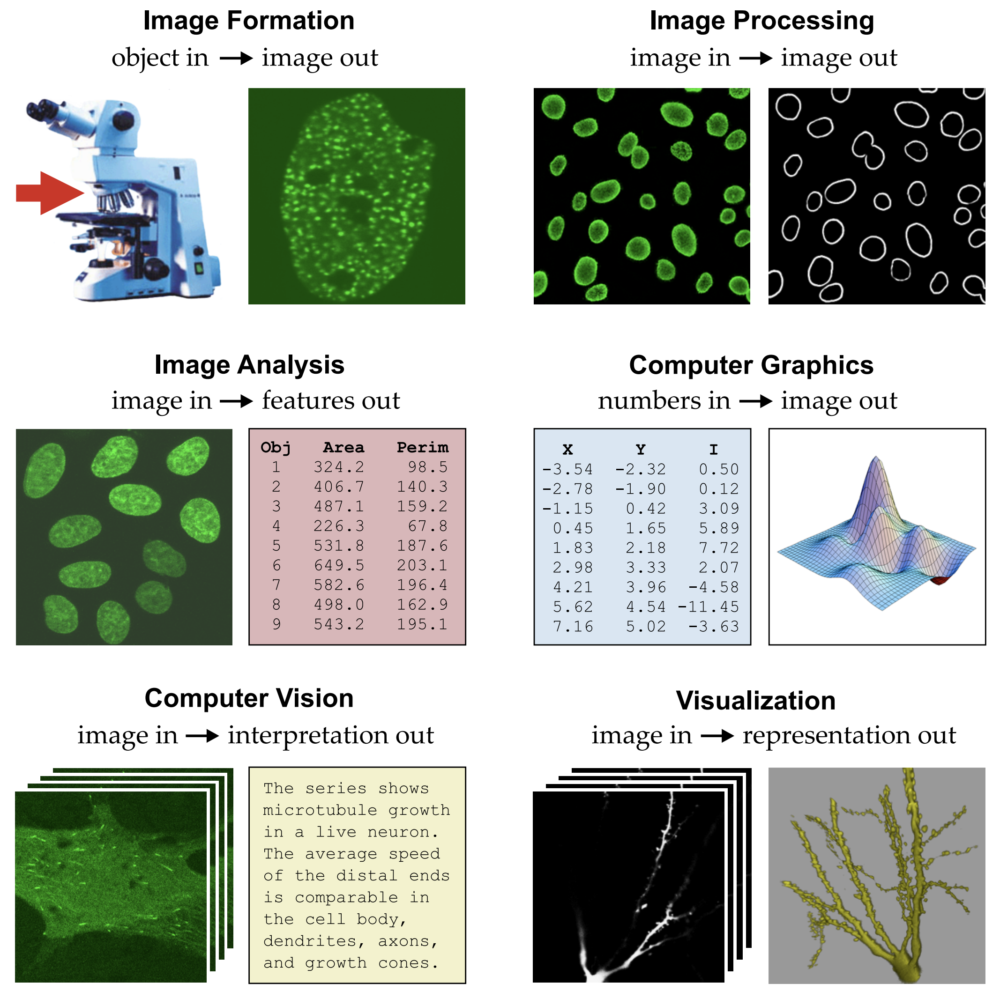

In [18]:
from IPython.display import Image
Image('./assets/digital_imaging.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

Below we provide a list of concepts and terms related to the acquisition and analysis of (medical) [digital images](https://en.wikipedia.org/wiki/Digital_imaging) that are important in the course. <br>
To guide the learner we have also provided links to more detailed information about the concepts and terms.


- **Image formation / Image reconstruction** (”bildedannelse” / "bilderekonstruksjon") 


- [**Pixel**](https://en.wikipedia.org/wiki/Pixel) ("bildeelement)

- [**Voxel**](https://en.wikipedia.org/wiki/Voxel) (“volum-element”)


- [**Imaging examination**](https://blog.radiology.virginia.edu/different-imaging-tests-explained) ("bildeundersøkelse")


- **Imaging modality** (“bildemodalitet”)  -  e.g. [MRI](https://en.wikipedia.org/wiki/Magnetic_resonance_imaging), [CT](https://en.wikipedia.org/wiki/CT_scan), [PET](https://en.wikipedia.org/wiki/Positron_emission_tomography), [ultrasound](https://en.wikipedia.org/wiki/Medical_ultrasound), [optical imaging](https://en.wikipedia.org/wiki/Medical_optical_imaging)


- [**Image processing**](https://en.wikipedia.org/wiki/Digital_image_processing) ("bildebehandling")


- [**Image editing**](https://en.wikipedia.org/wiki/Image_editing) ("bildeeditering" / "bildeforbedring")


- [**Image analysis**](https://en.wikipedia.org/wiki/Image_analysis) ("bildeanalyse”)


- [**Computer graphics**](https://en.wikipedia.org/wiki/Computer_graphics) ("datagrafikk”)


- [**Computer vision**](https://en.wikipedia.org/wiki/Computer_vision) ("datasyn")


- **Image understanding** ("automatisk bildetolkning”)


- [**Visualization**](https://en.wikipedia.org/wiki/Visualization_(graphics)) ("visualisering”)


- [**Neuroimaging**](https://en.wikipedia.org/wiki/Neuroimaging), or more restricted **brain imaging** ("hjerneavbildning")



## Image segmentation is "the holy grail" of image analysis and computer vision

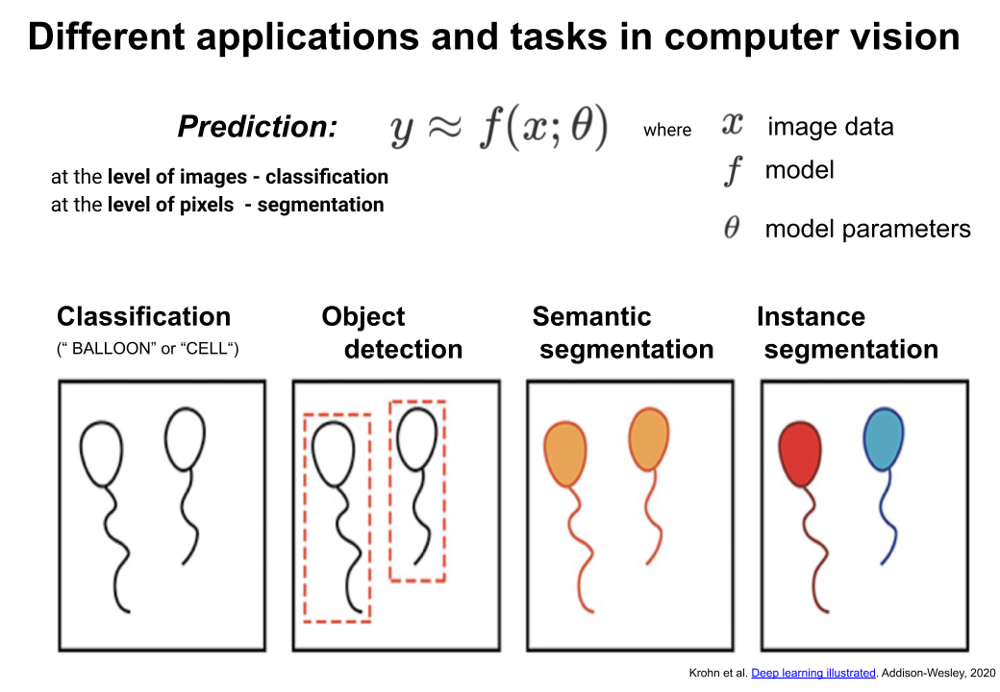

In [19]:
from IPython.display import Image
Image('./assets/image_classification_and_segmentation.png', width=800)

## Digital image

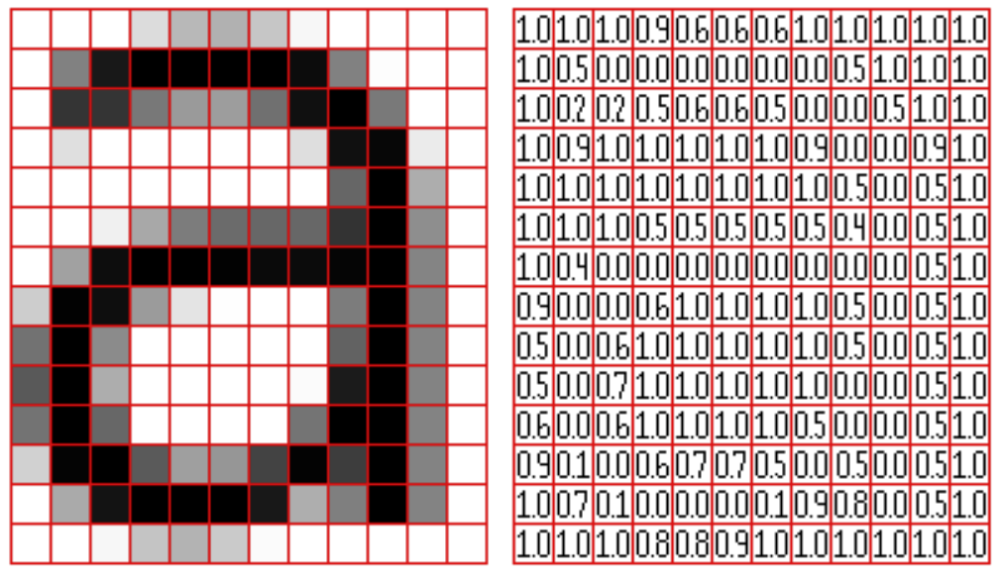

In [20]:
from IPython.display import Image
Image('./assets/pixel_grid.png', width=600)

https://pippin.gimp.org/image_processing/images/sample_grid_a_square.png

## Pixel density

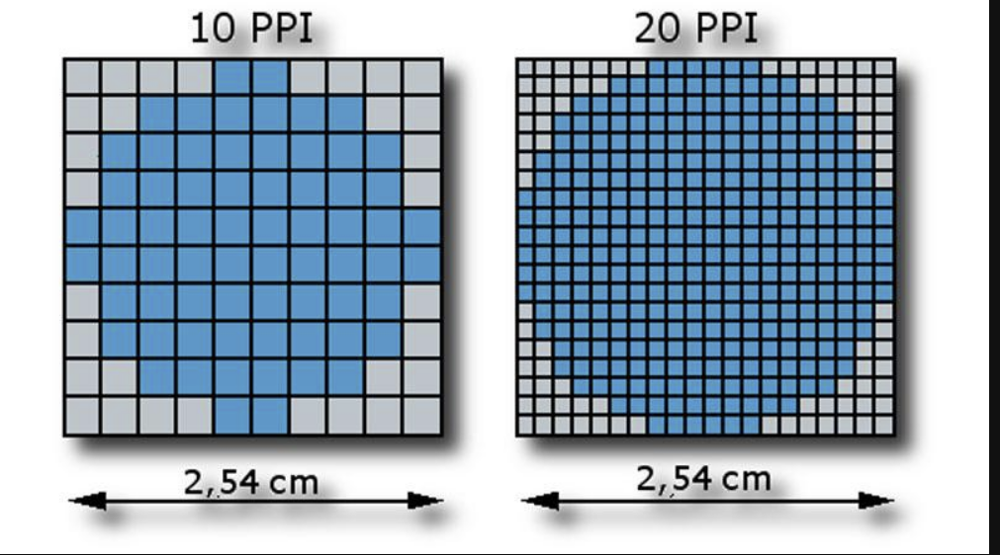

In [21]:
from IPython.display import Image
Image('./assets/pixel_density_ppi.png', width=600)

https://www.scientiamobile.com/wp-content/uploads/2018/12/Pixel-Density.jpg

Illustration of [pixel density](https://en.wikipedia.org/wiki/Pixel_density) (PPI = pixels per inch), a typical characteristic of display in smartphones and computer screens [[source](https://www.scientiamobile.com/what-is-pixel-density)]. This is also related to image display and acquisition matrices in medical imaging, i.e. number of pixels across the "Field of View" (FOV) in $x$ and $y$ direction denoted FOV$_x$ and FOV$_y$ (cfr. the figure)

## Signal intensity transformation

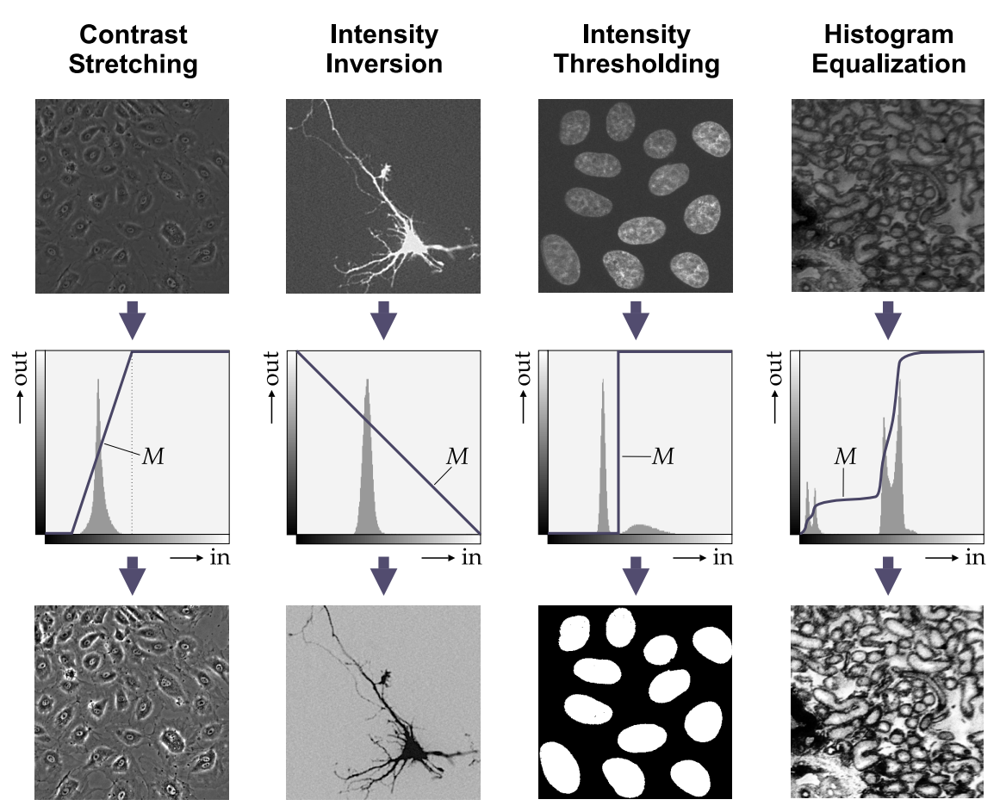

In [22]:
from IPython.display import Image
Image('./assets/intensity_transformations.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006

**Principles and examples of convolution filtering**. The value of an output pixel is computed as a linear combination (weighing and summation) of the value of the corresponding input
pixel and of its neighbors. The weight factor assigned to each input pixel is given by the _convolution kernel_ (denoted $K$). In principle, kernels can be of any size. Examples of commonly used
kernels of size $3 \times 3$ pixels include the averaging filter, the sharpening filter, and the _Sobel_ $x$- or
$y$-derivative filters. The _Gaussian filter_ is often used as a smoothing filter. It has a free parameter
(standard deviation $\sigma$) which determines the size of the kernel (usually cut off at $m = 3 \cdot \sigma$) and
therefore the degree of smoothing. The derivatives of this kernel are often used to compute image
derivatives at different scales, as for example in _Canny edge detection_. The scale parameter, $\sigma$,
should be chosen such that the resulting kernel matches the structures to be filtered.

## Convolution filtering

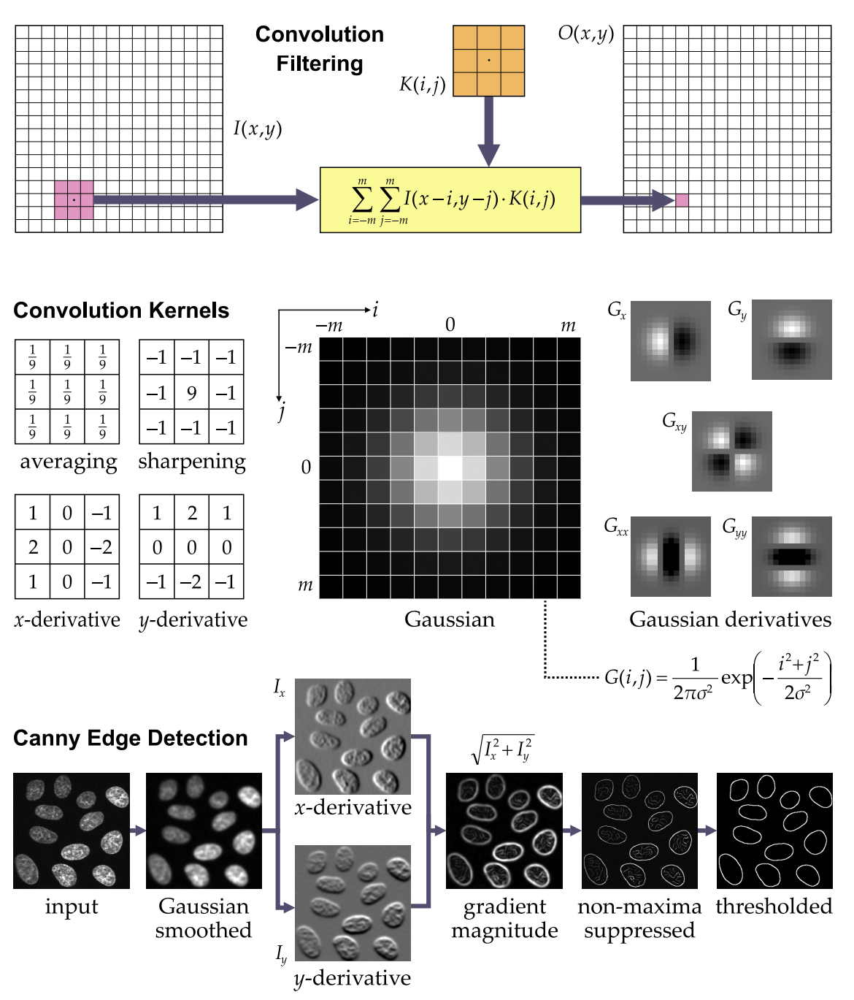

In [23]:
from IPython.display import Image
Image('./assets/convolution_filtering.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006

**Principles and examples of convolution filtering**. The value of an output pixel is computed as a linear combination (weighing and summation) of the value of the corresponding input
pixel and of its neighbors. 
The weight factor assigned to each input pixel is given by the [**convolution kernel**](https://en.wikipedia.org/wiki/Kernel_(image_processing)) (denoted $K$). In principle, kernels can be of any size. 

Examples of commonly used kernels of size $3 \times 3$ pixels include the **averaging** filter, the **sharpening** filter, and the [**Sobel**](https://en.wikipedia.org/wiki/Sobel_operator) $x$- or $y$-derivative filters. 

The **Gaussian filter** is often used as a *smoothing* filter. It has a free parameter
(standard deviation $\sigma$) which determines the size of the kernel (usually cut off at $m = 3\sigma$) and
therefore the degree of smoothing. The derivatives of this kernel are often used to compute image
derivatives at different scales, as for example in [**Canny edge detection**](https://en.wikipedia.org/wiki/Canny_edge_detector). The scale parameter, $\sigma$,
should be chosen such that the resulting kernel matches the structures to be filtered.

## Mathematical morphology

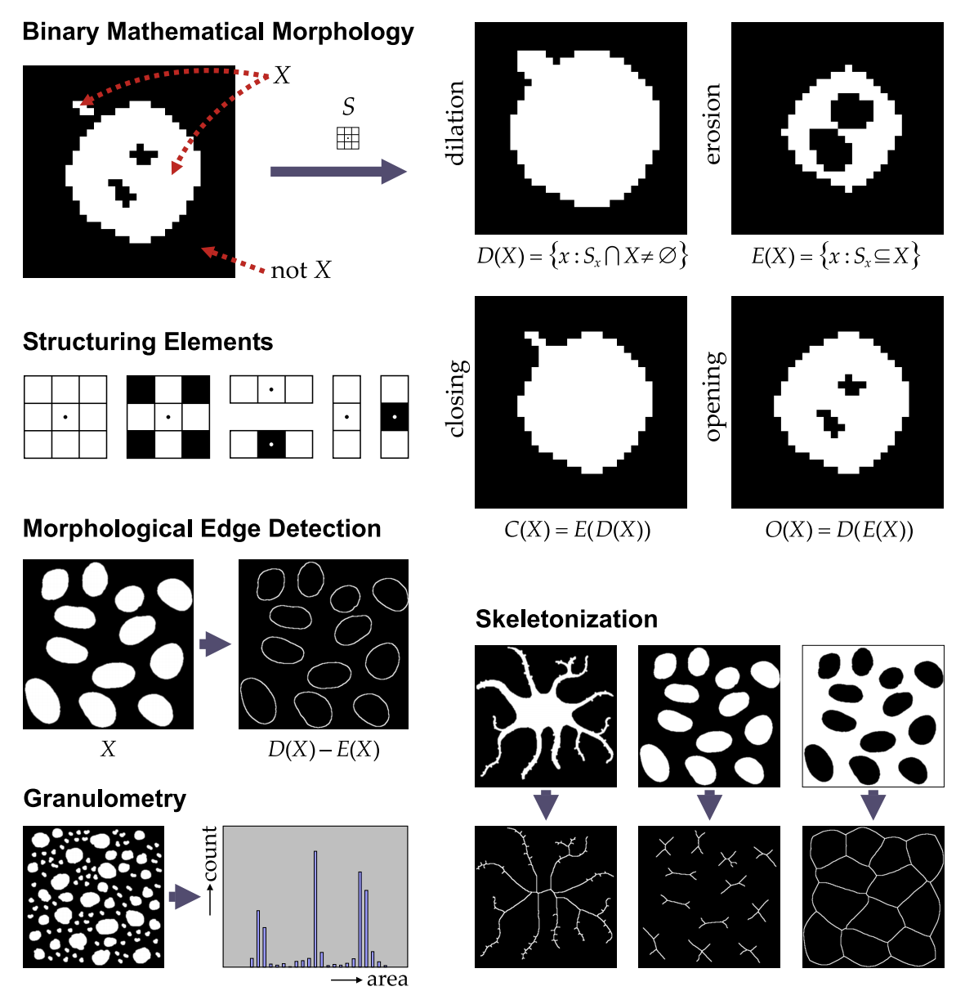

In [24]:
from IPython.display import Image
Image('./assets/binary_mathematical_morphology.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

**Principles and examples of [mathematical morphology](https://en.wikipedia.org/wiki/Mathematical_morphology) and binary morphological filtering**. An object in the image is
described as the set (denoted $X$) of all coordinates of pixels belonging to that object. Morphological filters process this set using a second set, known as the *structuring element* (denoted $S$). 

Here we focus on structuring elements that are symmetrical with respect to their center
element, $s = (0, 0)$, indicated by the dot. In that case, the *dilation of $X$* is defined as the set of all
coordinates $x$ for which the cross section of $S$ placed at $x$ (denoted $S_x$) with $X$ is not empty. The
*erosion of $X$* is the set of all $x$ for which $S_x$ is a subset of $X$. A dilation followed by an erosion (or
vice versa) is called *a closing* (versus *opening*). These operations are named after the effects they
produce, as illustrated. Many interesting *morphological filters* can be constructed by taking differences of two or more operations, such as in *morphological edge detection*. Other applications
include *skeletonization*, which consists in a sequence of thinning operations producing the basic
shape of objects, and *granulometry*, which uses a family of opening operations with increasingly
larger structuring elements to compute the size distribution of objects in an image.

## Coordinate transformation / image registration

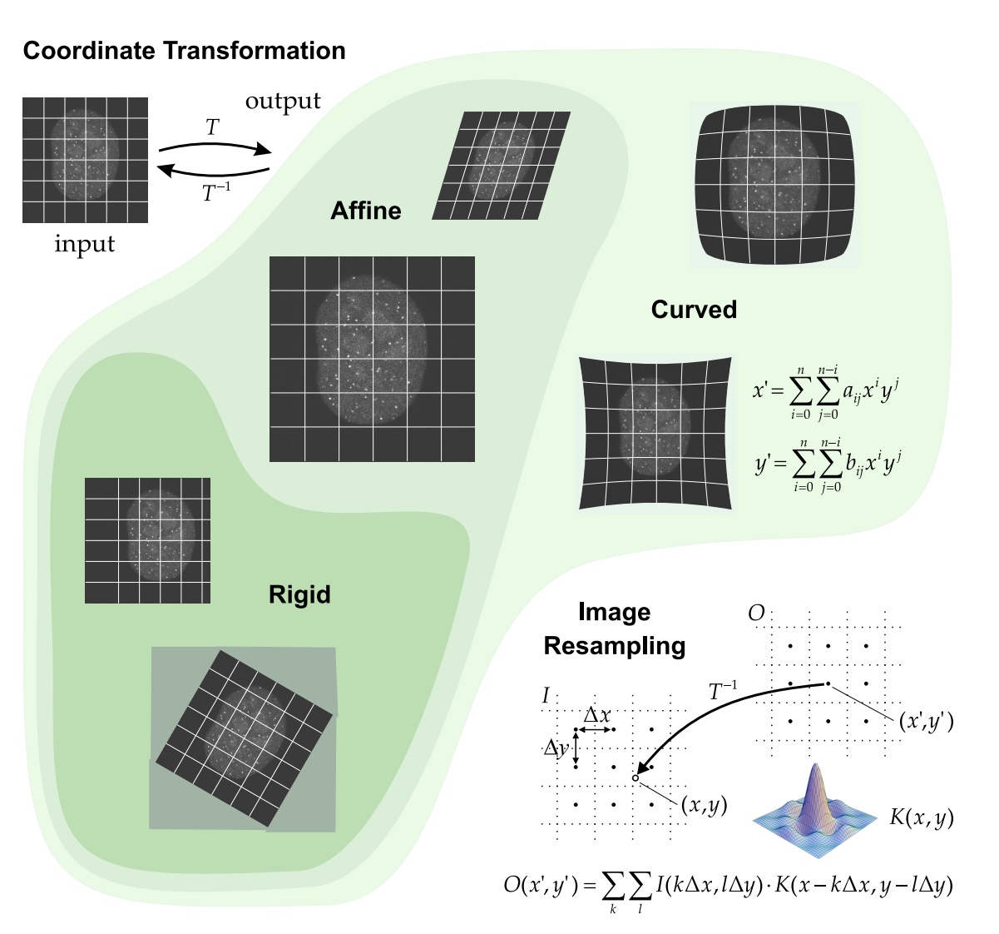

In [25]:
from IPython.display import Image
Image('./assets/coordinate_transformation.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

**Geometrical image transformation by coordinate transformation and image resampling**. The former is concerned with how input pixel positions are mapped to output pixel positions. Many types of transformations (denoted $T$) exist. The most frequently used types are (in
increasing order of complexity) **rigid transformations** (*translations* and *rotations*), **affine transformations** (*rigid transformations* plus *scalings* and *skewings*), and **curved transformations** (affine
transformations plus certain *nonlinear* or *elastic deformations*). 

These are defined (or can be approximated) by polynomial functions (with degree $n$ depending on the complexity of the transformation). **Image resampling** concerns the computation of the pixel values of the output image (denoted $O$) from the pixel values of the input image (denoted $I$). This is done by using the inverse transformation (denoted $T^{−1}$) to map output grid positions $(x', y')$ to input positions $(x, y)$. The value at this point is then computed by **interpolation** from the values at neighboring grid positions, using a weighing function, also known as the interpolation kernel (denoted $K$). This figure illustrates 2D transformations, but the same principles can be performed in 3D (typical in CT and MRI).


## Image restoration (noise suppression, intensity inhomogenetiy correction)

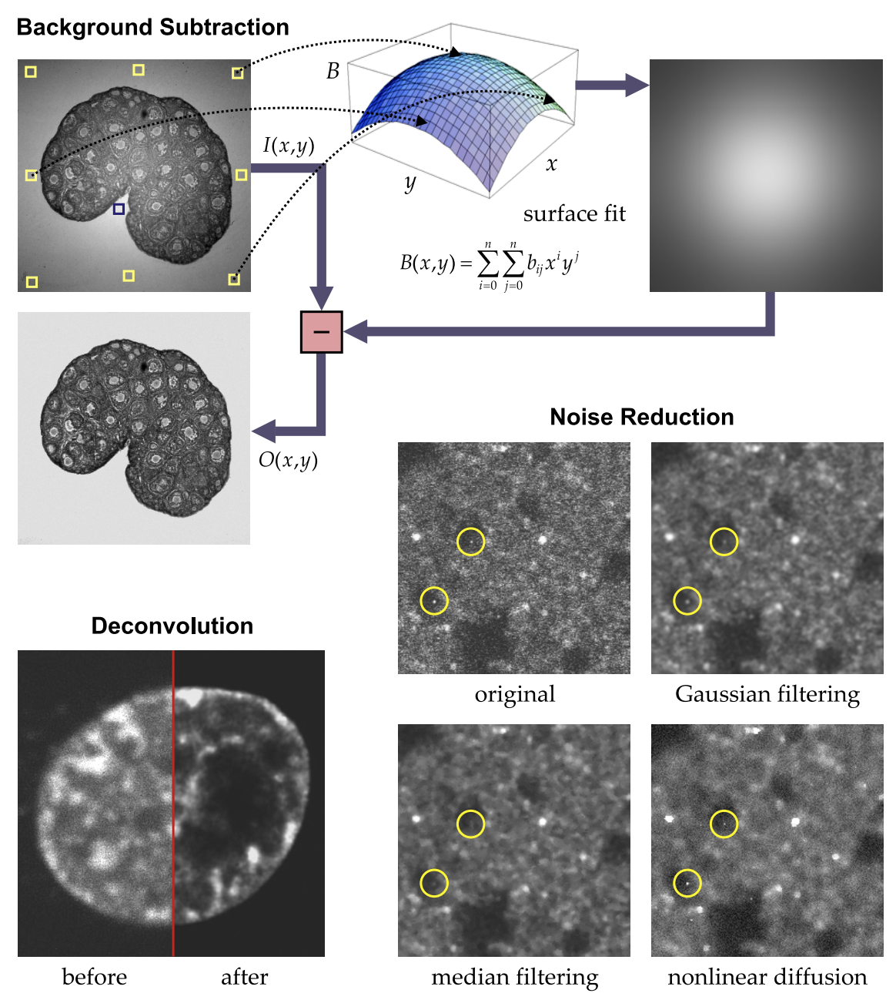

In [26]:
from IPython.display import Image
Image('./assets/image_restoration.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

Examples of the effects of image restoration operations: background subtraction (signal inhomogeneity correction, or biasfield corection), noise reduction, and deconvolution. Intensity gradients may be removed by subtracting a background
image. In some cases, this image may be obtained from the raw image itself by mathematically
fitting a polynomial surface function through the intensities at selected points (indicated by the
squares) corresponding to the background. Several filtering methods exist to reduce noise. Gaussian filtering blurs not only noise but all image structures. Median filtering is somewhat better at
retaining object edges but has the tendency to eliminate very small objects (compare the circles
in each image). Needless to say, the magnitude of these effects depends on the filter size. Nonlinear diffusion filtering was designed specifically to preserve object edges while reducing noise.
Finally, deconvolution methods aim to undo the blurring effects of the microscope optics and to
restore small details. More sophisticated methods are also capable of reducing noise.

## [Colocalization](https://en.wikipedia.org/wiki/Colocalization)

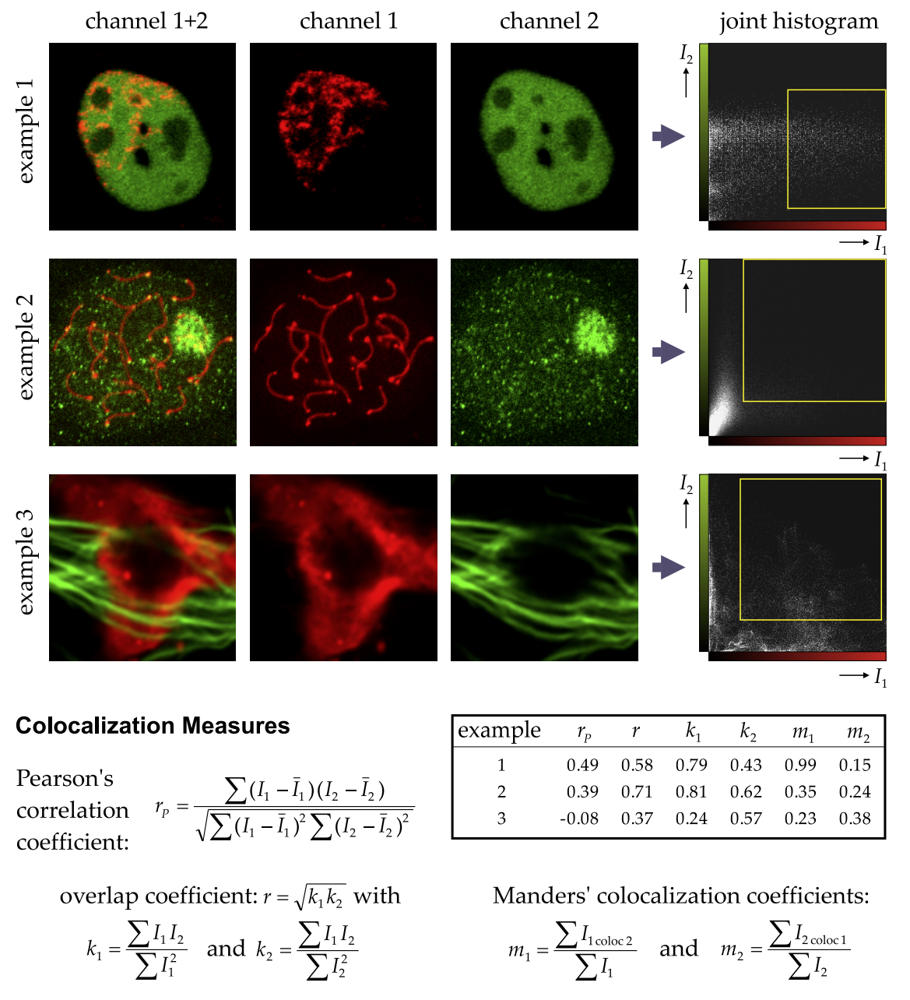

In [27]:
from IPython.display import Image
Image('./assets/colocalization.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

Commonly used measures for quantitative colocalization analysis. The aim of all these
measures is to express in numbers the degree of overlap between two fluorophores (captured in
well separated channels), indicating the presence of the corresponding labeled molecules in the
same or proximate physical locations (up to the optical resolution of the microscope). A visual impression of the co-occurrence of fluorophore intensities ($I_1$ and $I_2$) is given by the joint histogram
(also referred to as the scatter plot or fluorogram). 

Some colocalization measures are computed
over the entire images, while some are restricted to certain intensity ranges (indicated by the
squares in the joint histograms). Among the first are _Pearson’s correlation coefficient_ (denoted
$r_P$) and the so-called _overlap coefficient_ (denoted $r$ and computed from the subcoefficients $k_1$ and
$k_2$). Both coefficients are insensitive to intensity scalings (due to photobleaching or a difference
in signal amplification), while the former is also insensitive to intensity offsets (different background levels). The value of $r_P$ may range from $−1$ to $1$ and is therefore at odds with intuition.
Its squared value is perhaps more valuable as it expresses the quality of a least-squares fitting of a
line through the points in the scatter plot. The other measures range from $0$ to $1$. The value of $r$ is
meaningful only when the amount of fluorescence is approximately equal in both channels, that
is when $k_1$ and $k_2$ have similar values. 

_Manders’ colocalization coefficients_ (denoted $m_1$ and $m_2$)
are intuitively most clear but require careful separation of signal and background in both channels: the denominators are computed over the entire images, but the numerators sum only those
intensities in one channel for which the corresponding intensity in the other channel is within a
predefined range (the left and right and the top and bottom lines of the square region indicated
in the joint histogram, for $I_1$ and $I_2$ respectively).

## Volume and surface [rendering](https://en.wikipedia.org/wiki/Rendering_(computer_graphics))

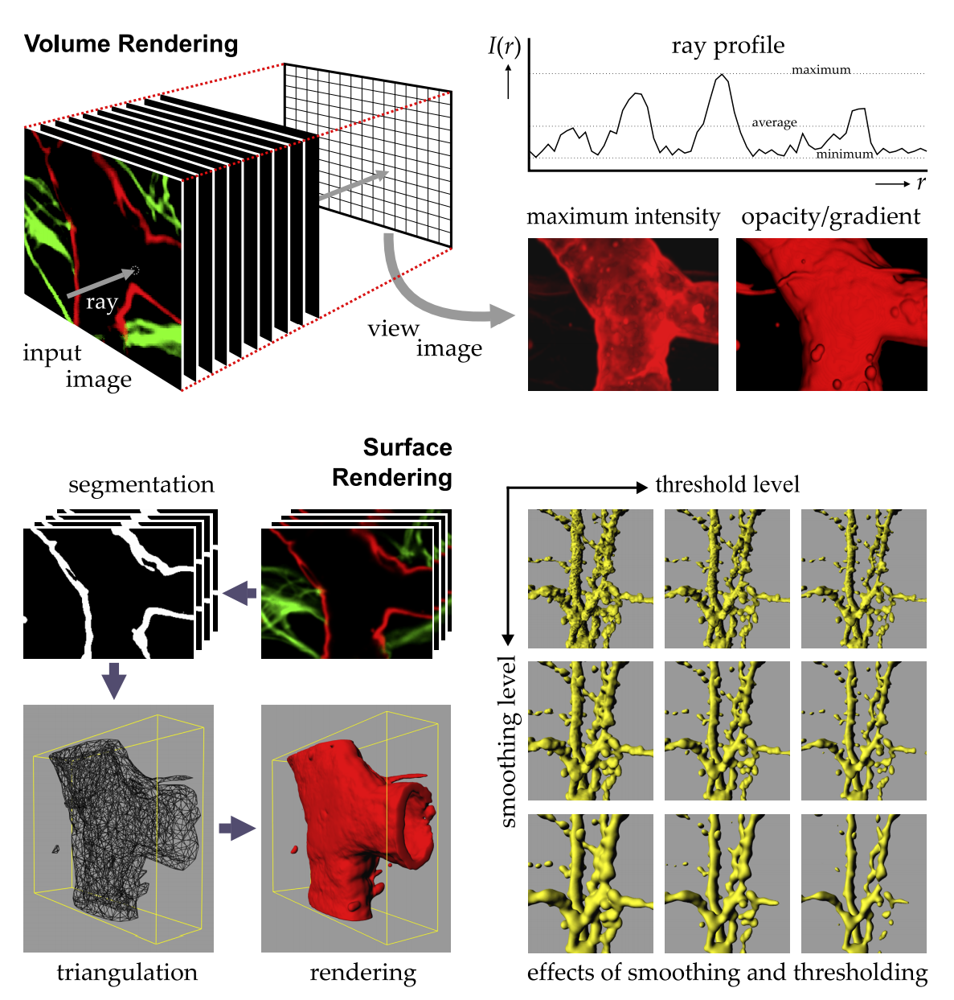

In [28]:
from IPython.display import Image
Image('./assets/volume_rendering.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](https://imagescience.org/meijering/publications/download/biap2006.pdf), 2006 (highly recommended!)

**Visualization of volumetric image data using volume rendering and surface rendering
methods**. *Volume rendering* methods do not require an explicit geometrical representation of
the objects of interest present in the data. A commonly used volume rendering method is *ray
casting*: for each pixel in the view image, a ray is cast into the data, and the intensity profile
along the ray is fed to a ray function, which determines the output value, such as the maximum,
average, or minimum intensity, or accumulated "opacity" (derived from intensity or gradient
magnitude information). 

By contrast, *surface rendering* methods require a segmentation of the
objects (usually obtained by thresholding), from which a surface representation (*triangulation*)
is derived, allowing very fast rendering by graphics hardware ([GPU](https://en.wikipedia.org/wiki/Graphics_processing_unit)). 
To reduce the effects of noise,
Gaussian smoothing is often applied as a preprocessing step prior to segmentation. As shown,
both operations have a substantial influence on the final result: by slightly changing the degree
of smoothing or the threshold level, objects may appear (dis)connected while in fact they are not.
Therefore it is recommended to establish optimal parameter values for both steps while inspecting
the effects on the original image data rather than looking directly at the renderings.

## Field of View

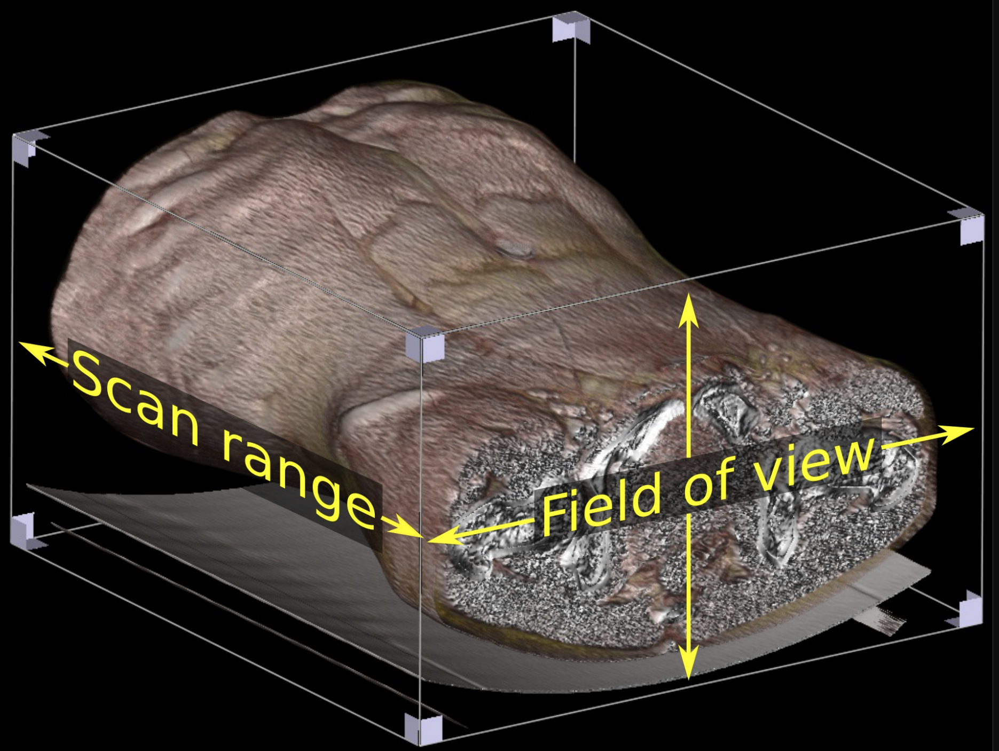

In [29]:
from IPython.display import Image
Image('./assets/abdominal_ct_fov.png', width=600)

https://upload.wikimedia.org/wikipedia/commons/d/de/Abdominal_CT_with_scan_range_and_field_of_view%2C_with_box_and_text.jpg

In computed tomography (abdominal CT pictured), the field of view ([FOV](https://en.wikipedia.org/wiki/Field_of_view)) multiplied by scan range creates a volume of voxels.<br> By Mikael Häggström, used with [permission](https://commons.wikimedia.org/wiki/User:Mikael_H%C3%A4ggstr%C3%B6m#Reusing_images) (CC0 1.0).

## Digital images as matrices

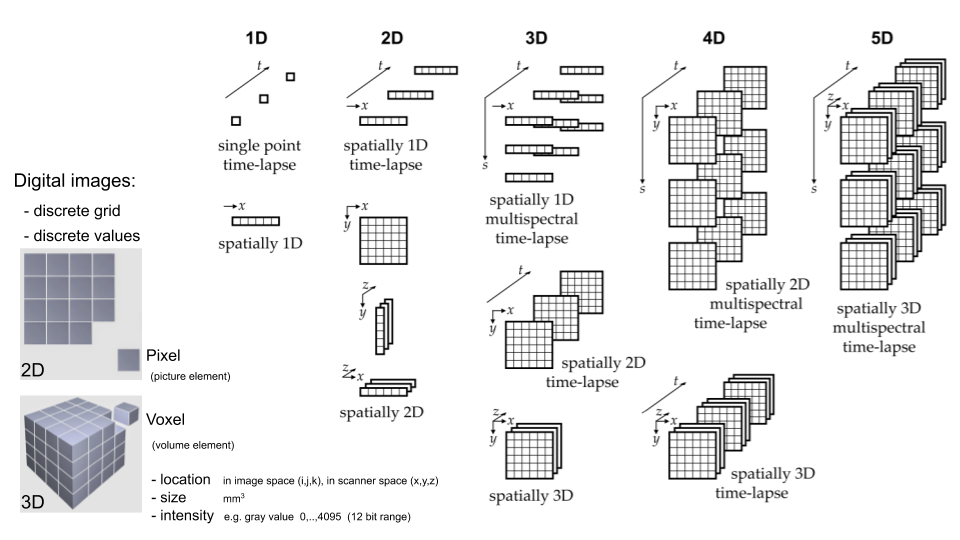

In [30]:
from IPython.display import Image
Image('./assets/images_as_matrices.png', width=800)

From Erik Meijering and Gert van Cappellen, [Biological Image Analysis Primer](http://www.imagescience.org/meijering/publications/download/biap2006.pdf), 2006.

**Images viewed as matrices**. The overview reflects some of the more frequently used modes of image acquisition in biological and medical imaging, where the number of dimensions is typically one to five, with each dimension corresponding to an independent physical parameter: three (usually denoted $x, y, z$) to space, one (usually denoted $t$) to time, and one to wavelength, or color, or more generally to any spectral parameter (we denote
this dimension $s$ here). 

**Images are discrete functions**, $I(x, y, z, t,s)$, with each set of coordinates yielding the value of a unique sample (indicated by the small squares, the number of which is obviously arbitrary here). 
Note that the dimensionality of an image (indicated in the top row) is given by the number of coordinates that are varied during acquisition. To avoid confusion in characterizing an image, it is advisable to add adjectives indicating which dimensions were scanned, rather than mentioning just dimensionality. 
For example, a *4D image may either be a spatially 2D multispectral time-lapse image, or a spatially 3D time-lapse image*.

## Images as tensors


A [tensor](https://en.wikipedia.org/wiki/Tensor) is a general mathematical construct which can be used in many settings:

* Scalar value (a number): 0-dimensional tensor 
* Vector: 1-dimensional tensor
* Matrix: 2-dimensional tensor
* Volume: 3-dimensional tensor
* ... etc.

In digital imaging we often make use of a *tensor-based representation*:

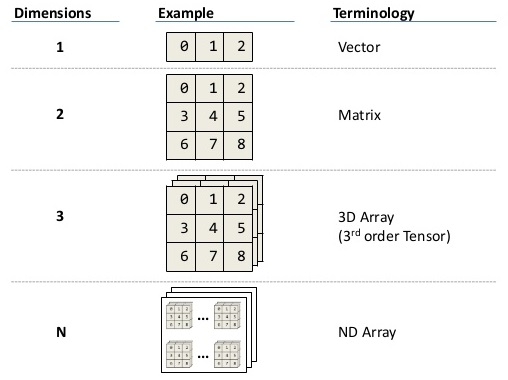

In [31]:
from IPython.display import Image
Image('./assets/image_tensors.jpg', width=600)

## -- End of general intro to digital imaging --

# `SimpleITK`: Toolkit for image filtering, segmentation, and registration

In [32]:
# There are a variety of ways to create an image. All images' initial value is well defined as zero.
image = sitk.Image(256, 128, 64, sitk.sitkInt16)

# Get the n-dimensional numpy array of voxel values
nda = sitk.GetArrayFromImage(image)
print('Number of voxels:', image.GetNumberOfPixels())
print('Image matrix,min and max voxel values:', nda.shape, nda.min(), ',', nda.max())

Number of voxels: 2097152
Image matrix,min and max voxel values: (64, 128, 256) 0 , 0


In [33]:
image = sitk.ReadImage('./assets/0.0-test_nifti.nii.gz')

In [34]:
# Accessing attributes

print(image.GetSize())
print(image.GetOrigin())
print(image.GetSpacing())
print(image.GetDirection())
print(image.GetNumberOfComponentsPerPixel())
print(image.GetWidth())
print(image.GetHeight())
print(image.GetDepth())
print(image.GetDimension())
print(image.GetPixelIDValue())
print(image.GetPixelIDTypeAsString())

(256, 256, 150)
(91.57415771484375, -146.60067749023438, -94.3832778930664)
(0.9374997615814209, 0.9374999403953552, 1.199998140335083)
(-0.022375107355647107, 0.016631400575325594, -0.9996113000252501, 0.97320826529911, 0.22922200922751446, -0.01797033970448012, -0.22883405979949867, 0.9732320725297765, 0.0213146839698619)
1
256
256
150
3
8
32-bit float


In [35]:
help(image.GetPixel)

Help on method GetPixel in module SimpleITK.SimpleITK:

GetPixel(*idx) method of SimpleITK.SimpleITK.Image instance
    Returns the value of a pixel.
    
    This method takes 2 parameters in 2D: the x and y index,
    and 3 parameters in 3D: the x, y and z index.



In [36]:
print('Original value:', image.GetPixel(128, 128, 64))
image.SetPixel(128,128, 64, 1)
print('New value:',image.GetPixel(128, 128, 64))

Original value: 1191.232421875
New value: 1.0


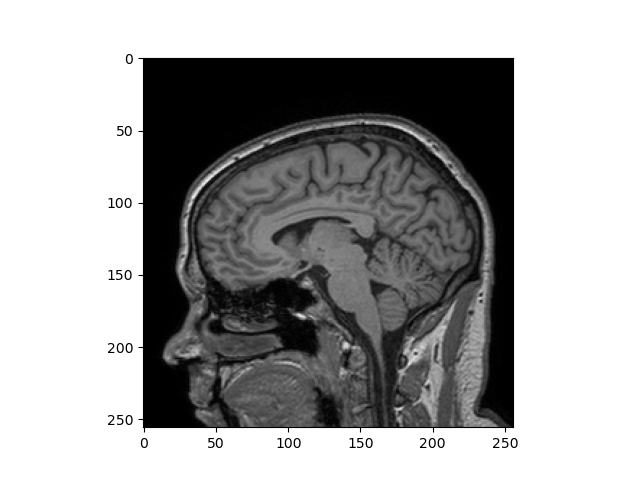

In [37]:
z = 70
slice = np.flipud(sitk.GetArrayViewFromImage(image)[z,:,:])   # Flip slice up-down for correct display
plt.imshow(slice, cmap="gray")
plt.show()

### Note on image formats

SimpleITK relies on the registered ImageIO components to indicate whether they can read a file and then perform the reading. This is done automatically.

In [38]:
file_reader = sitk.ImageFileReader()

# print the reader and see which ImageIO components are registered
print('\n',file_reader)


 itk::simple::ImageFileReader
  FileName: ""
  ExtractSize: [ ]
  ExtractIndex: [ ]
  Image Information:
    PixelType: Unknown pixel id
    Dimension: 0
    NumberOfComponents: 0
    Direction: [ ]
    Origin: [ ]
    Spacing: [ ]
    Size: [ ]
  OutputPixelType: Unknown pixel id
  LoadPrivateTags: 0
  ImageIOName: 
  Registered ImageIO:
	BMPImageIO ( *.bmp, *.BMP )
	BioRadImageIO ( *.PIC, *.pic )
	Bruker2dseqImageIO
	GDCMImageIO ( *.dcm, *.DCM, *.dicom, *.DICOM )
	GE4ImageIO
	GE5ImageIO
	GiplImageIO
	HDF5ImageIO ( *.hdf, *.h4, *.hdf4, *.h5, *.hdf5, *.he4, *.he5, *.hd5 )
	JPEGImageIO ( *.jpg, *.JPG, *.jpeg, *.JPEG )
	JPEG2000ImageIO ( *.j2k, *.jp2, *.jpt )
	LSMImageIO ( *.lsm, *.LSM )
	MGHImageIO
	MINCImageIO ( *.mnc, *.MNC, *.mnc2, *.MNC2 )
	MRCImageIO ( *.mrc, *.rec )
	MetaImageIO ( *.mha, *.mhd )
	NiftiImageIO ( *.nia, *.nii, *.nii.gz, *.hdr, *.img, *.img.gz )
	NrrdImageIO ( *.nrrd, *.nhdr )
	PNGImageIO ( *.png, *.PNG )
	StimulateImageIO ( *.spr )
	TIFFImageIO ( *.tif, *.TIF, *.ti

### A two-dimensional [Gabor filter](https://en.wikipedia.org/wiki/Gabor_filter)

(frequency and orientation representations of Gabor filters are similar to those of the human visual system, and they have been found to be particularly appropriate for texture representation and discrimination - see e.g. [[here](http://vision.psych.umn.edu/users/kersten/kersten-lab/courses/Psy5036W2017/Lectures/17_PythonForVision/Demos/html/2b.Gabor.html)]

In [39]:
img = sitk.GaborSource(size=[64]*2, frequency=.03)
def myshow(img):
    nda = sitk.GetArrayViewFromImage(img)
    plt.imshow(nda, cmap='gray')
myshow(img)

In [40]:
print('img direction', img.GetDirection())
print('img origin', img.GetOrigin())
print('img size', img.GetSize())
print('img depth', img.GetDepth())
print('img dimension', img.GetDimension())
print('img width', img.GetWidth())

img direction (1.0, 0.0, 0.0, 1.0)
img origin (0.0, 0.0)
img size (64, 64)
img depth 0
img dimension 2
img width 64


## $\rightarrow$ Your turn!

Play with Gabor filters of different orientation and spatial frequencies.
Check attributes, but pressing the tab key after the . by typing `img. `

In [41]:
help(sitk.GaborSource)

Help on function GaborSource in module SimpleITK.SimpleITK:

GaborSource(*args, **kwargs)
    GaborSource(itk::simple::PixelIDValueEnum outputPixelType=sitkFloat32, VectorUInt32 size=std::vector< unsigned int >(3, 64), VectorDouble sigma=std::vector< double >(3, 16.0), VectorDouble mean=std::vector< double >(3, 32.0), double frequency=0.4, VectorDouble origin=std::vector< double >(3, 0.0), VectorDouble spacing=std::vector< double >(3, 1.0), VectorDouble direction=std::vector< double >()) -> Image
    
    
    Generate an n-dimensional image of a Gabor filter.
    
    
    This function directly calls the execute method of GaborImageSource in order to support a procedural API
    
    
    See:
     itk::simple::GaborImageSource for the object oriented interface



In [42]:
# Hint (vary these parameters):
size = 256 
freq = 0.03
dir = (1.0, 1.0, 0.0, 1.0)
spac = (1.0, 1.0)
orig = (.0, .0)
my_img = sitk.GaborSource(
    sitk.sitkFloat32, 
    size=[size]*2, 
    sigma=[size*.2]*2, 
    mean=[size*0.5]*2, 
    frequency=freq,
    origin=orig,
    spacing=spac,
    direction=dir)


myshow(my_img)

In [43]:
# Get the image as a numpy array
my_gabor = sitk.GetArrayViewFromImage(my_img)
print('shape:', my_gabor.shape)
print('min and max:', my_gabor.min(), ', ',  my_gabor.max())

shape: (256, 256)
min and max: -0.9448353 ,  1.0


In [44]:
my_gabor.view()

array([[ 1.0343890e-03,  7.4606598e-04,  3.9853458e-04, ...,
        -6.0126319e-18,  3.9853458e-04,  7.4606598e-04],
       [ 7.8324956e-04,  4.1839737e-04, -6.3122992e-18, ...,
         4.1839737e-04,  7.8324956e-04,  1.0859426e-03],
       [ 4.3908259e-04, -6.6243742e-18, -4.8301852e-04, ...,
         8.2197279e-04,  1.1396307e-03,  1.3862911e-03],
       ...,
       [-6.9492262e-18,  4.6061474e-04,  8.6228148e-04, ...,
        -3.9711452e-14, -4.3912536e-14, -4.4902548e-14],
       [ 4.3908259e-04,  8.2197279e-04,  1.1396307e-03, ...,
        -4.1859775e-14, -4.2803509e-14, -4.1404715e-14],
       [ 7.8324956e-04,  1.0859426e-03,  1.3209828e-03, ...,
        -4.0787032e-14, -3.9454134e-14, -3.6514106e-14]],
      shape=(256, 256), dtype=float32)

## $\rightarrow$ Side step:

### A more advanced (and illustrative*) follow-up on the Gabor filter - modified from [here](http://vision.psych.umn.edu/users/kersten/kersten-lab/courses/Psy5036W2017/Lectures/17_PythonForVision/Demos/html/2b.Gabor.html)

*) illustrative regarding visualization and user interaction, and regarding how to implement mathematical expressions and equations in Python

[ _This side step make use of code from the Computational Vision Laboratory ([Prof. Daniel J Kersten](https://cla.umn.edu/about/directory/profile/kersten)) in the Psychology Department, University of Minnesota for the [Psy 5036W (2017)](https://drive.google.com/drive/folders/0B9OrRM0RlZMgMHoxYk50SHZmZG8) course and its **PythonForVision** lab_.]

http://vision.psych.umn.edu/users/kersten/kersten-lab/courses/Psy5036W2017/Lectures/17_PythonForVision/

In [45]:
def myimshow(I, **kwargs):
    # utility function to show image
    plt.figure();
    plt.axis('off')
    plt.imshow(I, cmap=plt.gray(), **kwargs)

A general type of Gabor filter can be defined ([ref](https://en.wikipedia.org/wiki/Gabor_filter)):

$$
g(x,y;\lambda,\theta,\psi,\sigma,\gamma) = \exp\left(-\frac{x'^2+\gamma^2y'^2}{2\sigma^2}\right)\exp\left(i\left(2\pi\frac{x'}{\lambda}+\psi\right)\right)
$$

where $x' = x \cos\theta + y \sin\theta$ and  $y' = -x \sin\theta + y \cos\theta$ 

Implementation of a type of Gabor filter which satisfies the neurophysiological constraints for [simple cells](https://en.wikipedia.org/wiki/Simple_cell):

$$
\psi (x; \omega, \theta, K) = \left[\frac{\omega^2}{ 4 \pi K^2} \exp  \{-(\omega^2/8K^2)[4(x\cdot(cos\theta, sin\theta))^2 + (x \cdot ( -sin \theta, cos \theta))^2]\} \right] \times \left[ \exp \{ iwx \cdot (cos\theta, sin\theta) \} exp(K^2/2) \right]
$$

In [46]:
def genGabor(sz, omega, theta, func=np.cos, K=np.pi):
    radius = (int(sz[0]/2.0), int(sz[1]/2.0))
    [x, y] = np.meshgrid(range(-radius[0], radius[0]+1), range(-radius[1], radius[1]+1))

    x1 = x * np.cos(theta) + y * np.sin(theta)
    y1 = -x * np.sin(theta) + y * np.cos(theta)
    
    gauss = omega**2 / (4*np.pi * K**2) * np.exp(- omega**2 / (8*K**2) * ( 4 * x1**2 + y1**2))
#     myimshow(gauss)
    sinusoid = func(omega * x1) * np.exp(K**2 / 2)
#     myimshow(sinusoid)
    gabor = gauss * sinusoid
    return gabor

np.float64(1.51403e-05)

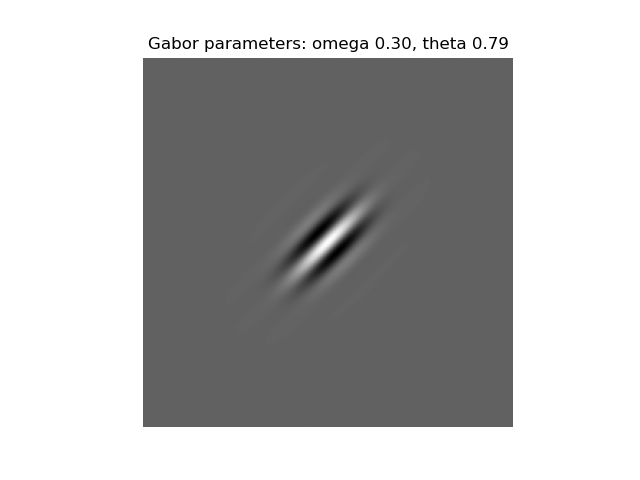

In [47]:
omega = 0.3
theta = np.pi/4
g = genGabor((256,256), omega, theta, func=np.cos) 
# change func to "cos", "sin" can generate sin gabor or cos gabor, here we pass a function name as a parameter
myimshow(g)
plt.title(r'Gabor parameters: omega %.2f, theta %.2f' % (omega, theta))
np.mean(g).round(10)

NOTE: This (`interact`) seems not to work when using `jupter lab`, i.e. try `jupyter notebook` instead<br>  (see: https://stackoverflow.com/questions/49542417/how-to-get-ipywidgets-working-in-jupyter-lab)

In [48]:
from ipywidgets import interact, interactive, fixed, Output
from IPython.display import display, clear_output

gabor_out = Output()

def demoGabor(theta, omega):
    with gabor_out:
        clear_output(wait=True)
        myimshow(genGabor((128,128), omega, theta))
        plt.show()

interact(demoGabor, theta=(0,np.pi, np.pi/8), omega=(0.1,1,0.1))
display(gabor_out)

interactive(children=(FloatSlider(value=1.5707963267948966, description='theta', max=3.141592653589793, step=0…

Output()

### Generate a Gabor filterbank

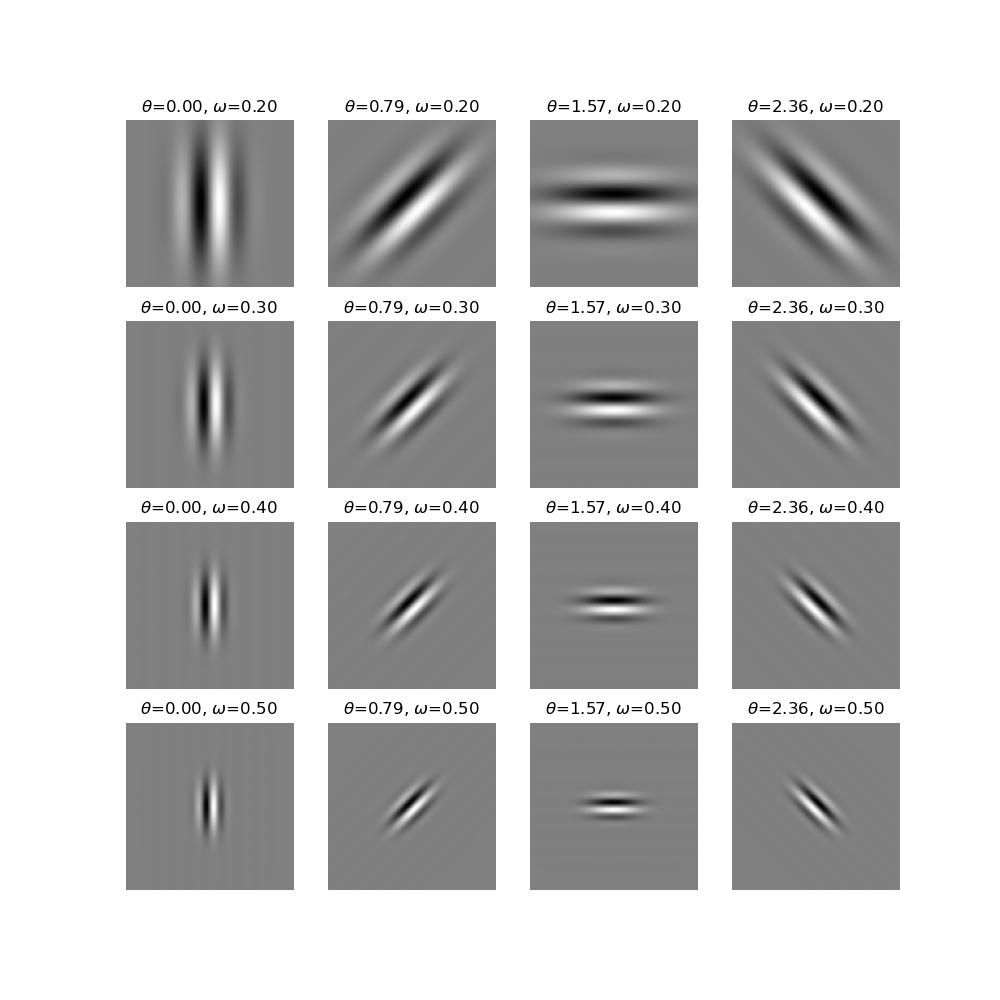

In [49]:
theta = np.arange(0, np.pi, np.pi/4) # range of theta
omega = np.arange(0.2, 0.6, 0.1) # range of omega
params = [(t,o) for o in omega for t in theta]
sinFilterBank = []
cosFilterBank = []
gaborParams = []
for (theta, omega) in params:
    gaborParam = {'omega':omega, 'theta':theta, 'sz':(128, 128)}
    sinGabor = genGabor(func=np.sin, **gaborParam)
    cosGabor = genGabor(func=np.cos, **gaborParam)
    sinFilterBank.append(sinGabor)
    cosFilterBank.append(cosGabor)
    gaborParams.append(gaborParam)

plt.figure(figsize=(10, 10))
n = len(sinFilterBank)
for i in range(n):
    plt.subplot(4,4,i+1)
    plt.title(r'$\theta$={theta:.2f}, $\omega$={omega:.2f}'.format(**gaborParams[i]))
    plt.axis('off'); plt.imshow(sinFilterBank[i])

## Apply filterbank to a zebra image using 2D convolution

(cfr. http://vision.psych.umn.edu/users/kersten/kersten-lab/courses/Psy5036W2017/Lectures/17_PythonForVision/Demos/html/2b.Gabor.html)

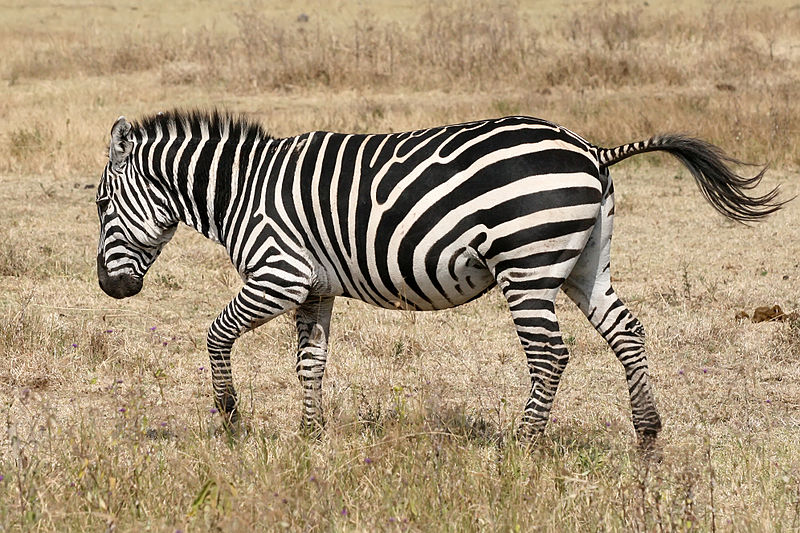

In [50]:
from IPython.display import Image
Image('./assets/Zebra_running_Ngorongoro.jpg', width=500)

https://commons.wikimedia.org/wiki/File:Zebra_running_Ngorongoro.jpg

In [51]:
from skimage.color import rgb2gray
from scipy.signal import convolve2d
from matplotlib import gridspec
zebra = rgb2gray(plt.imread('./assets/Zebra_running_Ngorongoro.jpg'))
#sinGabor = sinFilterBank[8]
#sinGabor = sinFilterBank[1]
#%time res = convolve2d(zebra, sinGabor, mode='valid') # Will take about one minute

In [52]:
def Gabor_convolution_response(input, gabor):
    res = convolve2d(input, gabor, mode='valid')  # Will take about one minute
    
    # Create figure and GridSpec
    fig = plt.figure(figsize=(15, 4))
    gs = gridspec.GridSpec(1, 3, width_ratios=[3, 1, 3])
    
    # Explicitly create and manage axes
    ax0 = plt.subplot(gs[0])
    ax0.imshow(zebra)
    ax0.set_title("Zebra")
    
    ax1 = plt.subplot(gs[1])
    ax1.imshow(gabor, cmap='gray')
    ax1.set_title("sinGabor")
    
    ax2 = plt.subplot(gs[2])
    ax2.imshow(res, cmap='gray')
    ax2.set_title("Response")
    
    fig.tight_layout()
    plt.show()
    return res


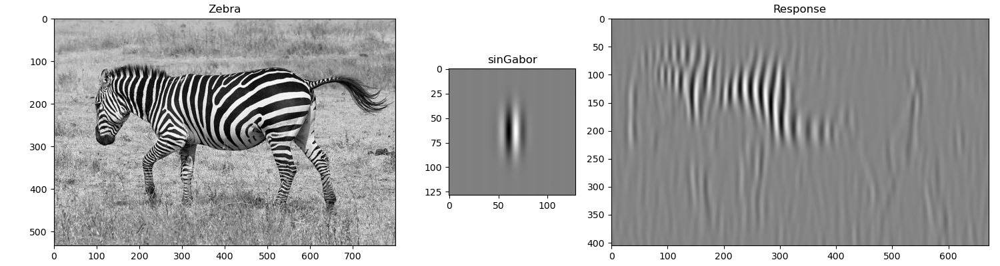

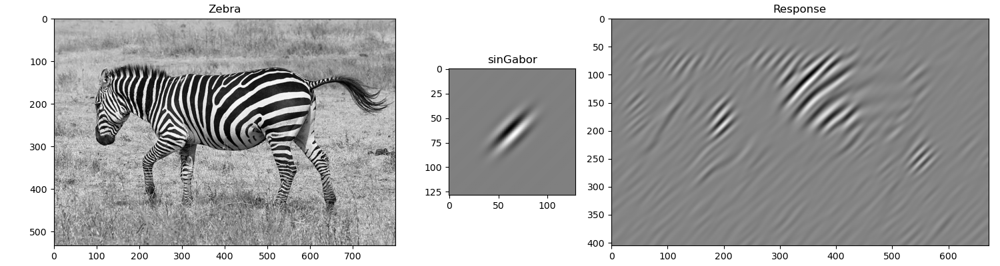

CPU times: user 12.2 s, sys: 150 ms, total: 12.3 s
Wall time: 12.4 s


In [53]:
%%time
res8 = Gabor_convolution_response(zebra, sinFilterBank[8])
res9 = Gabor_convolution_response(zebra, sinFilterBank[9])

### [ More on this topic (spatial filtering) in the lectures and notebooks on deep learning and CNNs (link) ]

# [`imageio`](https://imageio.github.io) : Python library for reading and writing images

We read a single slice four-channel MR image in DICOM-format (these data will be used later in the course)

In [54]:
channels = ['FLASH', 'DESS', 'FISP', 'PSIF']
nb_channels = len(channels)

In [55]:
images = [imageio.v2.imread(f'./assets/{channel.lower()}_060.dcm') for channel in channels] 

In [56]:
print('Channels:')
chns = [print(f'./assets/{channel.lower()}_060.dcm') for channel in channels]

Channels:
./assets/flash_060.dcm
./assets/dess_060.dcm
./assets/fisp_060.dcm
./assets/psif_060.dcm


Number of rows and columns in the first (counting from 0) channel image:

In [57]:
nrow, ncol = images[0].shape
print('nrow=%d, ncol=%d' % (nrow,ncol))

nrow=256, ncol=256


## $\rightarrow$ Your turn:

> - Find max signal intensity (SI) and min SI in the FLASH channel
> - Make a histogram of the signal intensities in FLASH (test the effect of binning: i.e. number of bins)

In [58]:
# My code (with hints)

# min = images[0].min(); max = images[0].max()

# bins=50
# plt.hist(images[0].flatten(),bins=bins)
# plt.title("Histogram of %s (min=%d, max=%d)" % (channels[0], min, max))
# plt.show()

Make a (2x2) figure (miltipanel display) of the channel images:

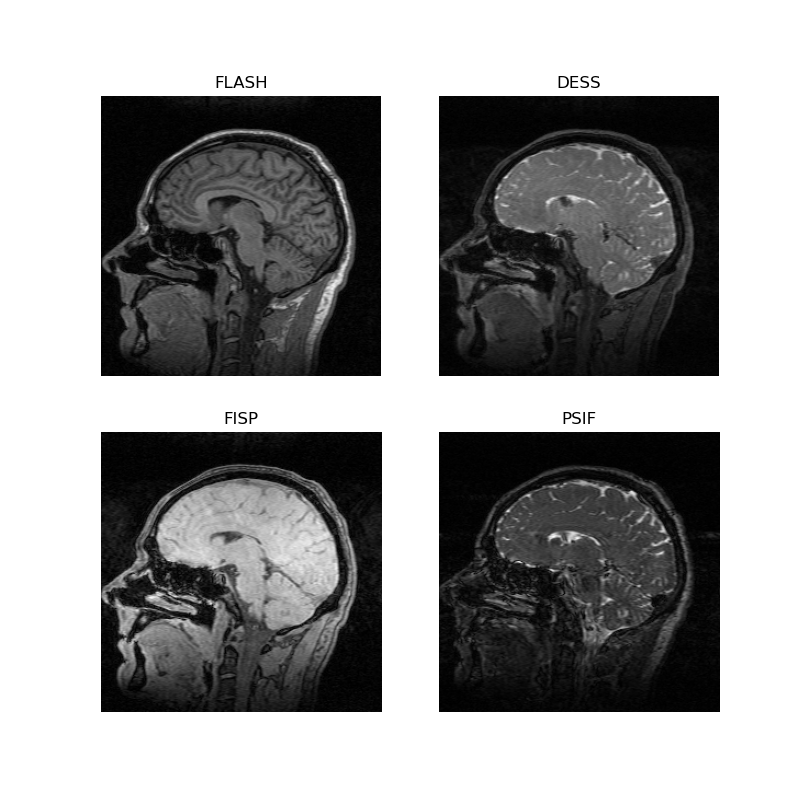

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
ax = axes.ravel()

for i, im in enumerate(images):
    ax[i].imshow(im, cmap='gray')
    ax[i].set_title(channels[i])
    ax[i].axis('off')

plt.show()

**$\rightarrow$ Your turn!**

> - Make a figure displaying the four channel images on one row

## Read files and display training masks and image data

(256, 256, 3)


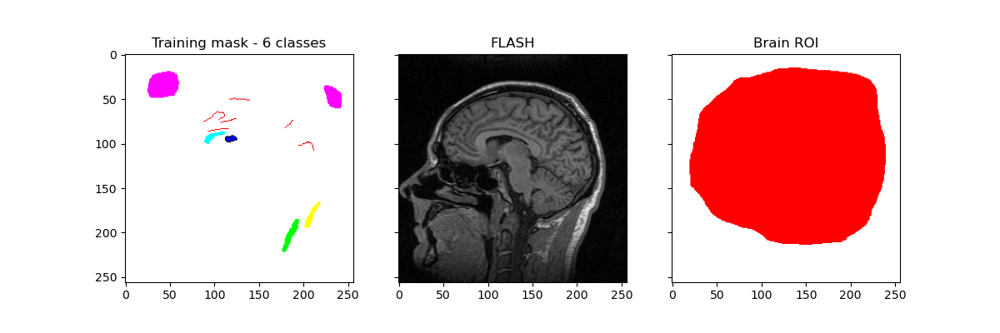

In [60]:
# Classes (color-coded): air, gm, wm, csf, fat, mus(cle)
train_mask = imageio.v2.imread("./assets/flash_060_training_mask_6cla.png")
roi_mask = imageio.v2.imread("./assets/flash_060_brain_mask.png")
print(train_mask.shape)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
ax = axes.ravel()
ax[0].imshow(train_mask)
ax[0].set_title("Training mask - 6 classes")
ax[1].imshow(images[0], cmap='gray')
ax[1].set_title("FLASH")
ax[2].imshow(roi_mask)
ax[2].set_title("Brain ROI")
plt.show()

In [61]:
# Number of occurences of each unique color (class label in training mask) in descending order
from collections import Counter
Counter([tuple(colors) for i in train_mask for colors in i]).most_common()

[((np.uint8(255), np.uint8(255), np.uint8(255)), 63519),
 ((np.uint8(255), np.uint8(0), np.uint8(255)), 1250),
 ((np.uint8(0), np.uint8(255), np.uint8(0)), 250),
 ((np.uint8(255), np.uint8(255), np.uint8(0)), 170),
 ((np.uint8(255), np.uint8(0), np.uint8(0)), 136),
 ((np.uint8(0), np.uint8(255), np.uint8(255)), 129),
 ((np.uint8(0), np.uint8(0), np.uint8(255)), 51),
 ((np.uint8(0), np.uint8(0), np.uint8(0)), 31)]

In [62]:
# Count the number of occurences of pixels in ROI mask
Counter([tuple(colors) for i in roi_mask for colors in i]).most_common()

[((np.uint8(255), np.uint8(0), np.uint8(0)), 35822),
 ((np.uint8(255), np.uint8(255), np.uint8(255)), 29714)]

# [`scikit-image`](https://scikit-image.org): Image processing in Python

In [63]:
from skimage import filters
from skimage import restoration

## We use the FLASH channel image

In [64]:
# Use the FLASH image from above
brain = images[0]
print('Min signal intensity:', np.min(brain), 'Max:', np.max(brain) )
print('Matrix:', brain.shape)
print('Pixel type:', brain.dtype)
brain = brain.astype(float)

Min signal intensity: 0 Max: 357
Matrix: (256, 256)
Pixel type: int16


## Image noise and noise suppression

### Any MRI aquisition is hampered with image noise (typically random and at high spatial frquencies

There are two types of denoising procedures in MRI
 - pre-reconstruction (e.g. repeat number of measurements (NEX > 1) and do averaging before image reconstruction)
 - post acquisition (e.g. noise filtering)

![image noise](assets/noise-in-MRI.png)

## Noise removal by image filtering  - comparison of methods

[Gauss](https://en.wikipedia.org/wiki/Gaussian_filter)-filtrering, [Median](https://en.wikipedia.org/wiki/Median_filter)-filtrering, [Total Variation](https://en.wikipedia.org/wiki/Total_variation_denoising) filtrering


**Reading a brain image from disk, define parameters and their values for the various noise filtering algorithms**

In [65]:
brain = brain / np.max(brain)  # normalizing to float in [0, 1]

def disk(radius):
    return np.ones((radius,radius))

r = 3
sigma = 2
weight = 0.01
med_brain = filters.median(brain, disk(r))
tv_brain = restoration.denoise_tv_chambolle(brain, weight=weight)
gaussian_brain = filters.gaussian(brain, sigma=sigma)

/var/folders/1g/_4x26lps6mgg1tr73d7g2bmh0000gp/T/ipykernel_64344/1090413787.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  brain = brain / np.max(brain)  # normalizing to float in [0, 1]


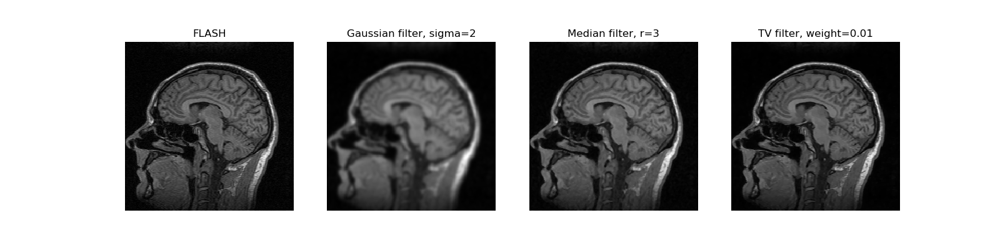

In [66]:
plt.figure(figsize=(16, 4))
plt.subplot(141)
plt.imshow(brain, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('FLASH')
plt.subplot(142)
plt.imshow(gaussian_brain, cmap='gray',
           interpolation='nearest')
plt.axis('off')
plt.title('Gaussian filter, sigma=%d' % (sigma))
plt.subplot(143)
plt.imshow(med_brain, cmap='gray',
           interpolation='nearest')
plt.axis('off')
plt.title('Median filter, r=%d' % (r))
plt.subplot(144)
plt.imshow(tv_brain, cmap='gray',
           interpolation='nearest')
plt.axis('off')
plt.title('TV filter, weight=%.2f' % (weight))
plt.show()

## $\rightarrow$ Your turn:

> Test the effect of "hyperparameters", the filtering parameter values: $r$, $sigma$, $weight$

## [Immunohistochemical](https://en.wikipedia.org/wiki/Immunohistochemistry) staining and color separation

Example from the <a href="https://scikit-image.org/docs/dev/auto_examples/color_exposure/plot_ihc_color_separation.html#sphx-glr-auto-examples-color-exposure-plot-ihc-color-separation-py">scikit-image</a>-documentation:

Color deconvolution consists in the separation of features by their colors.

In this example we separate the immunohistochemical (IHC) staining from the [hematoxylin](https://en.wikipedia.org/wiki/Haematoxylin) counterstaining. The separation is achieved with the method described in [1] and known as “color deconvolution”.

The IHC staining expression of the [FHL2](https://en.wikipedia.org/wiki/FHL2) protein is here revealed with diaminobenzidine ([DAB](https://en.wikipedia.org/wiki/3,3%27-Diaminobenzidine)) which gives a brown color.

[1] A. C. Ruifrok and D. A. Johnston, “Quantification of histochemical staining by color deconvolution,” Analytical and quantitative cytology and histology / the International Academy of Cytology [and] American Society of Cytology, vol. 23, no. 4, pp. 291-9, Aug. 2001. [[link](https://pubmed.ncbi.nlm.nih.gov/11531144)]  [[PDF](https://www.researchgate.net/profile/Arnout-Ruifrok/publication/319879820_Quantification_of_histochemical_staining_by_color_deconvolution/links/5aa8d1010f7e9b0ea307cc58/Quantification-of-histochemical-staining-by-color-deconvolution.pdf)]

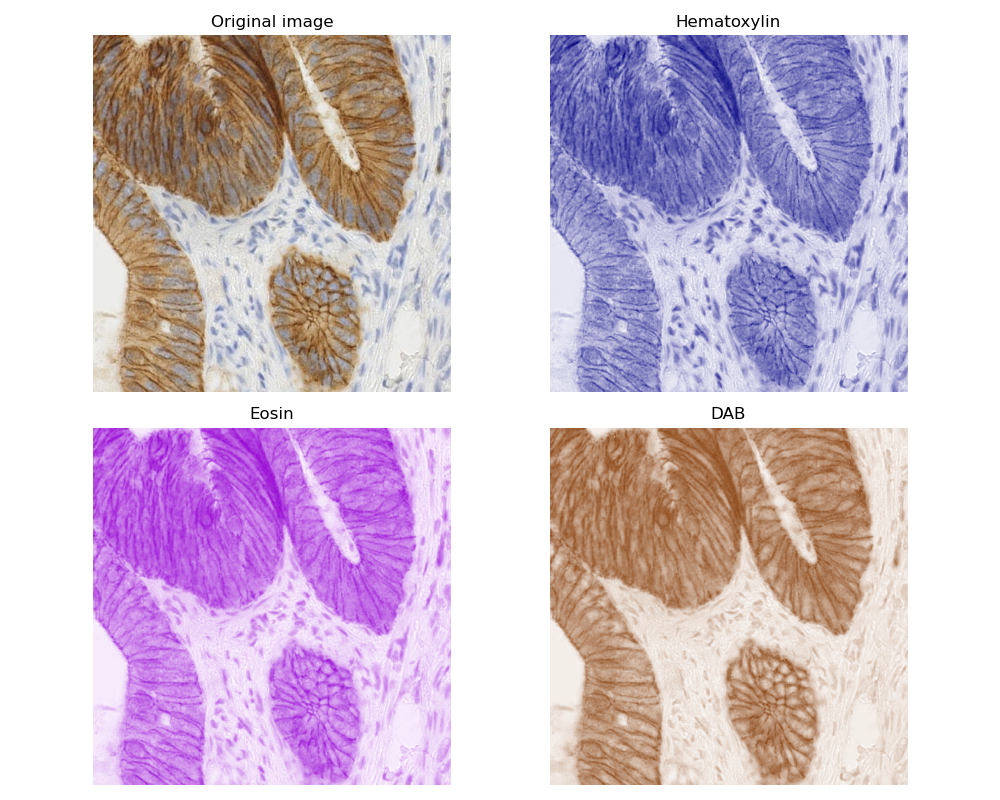

In [67]:
import matplotlib.pyplot as plt

from skimage import data
from skimage.color import rgb2hed
from matplotlib.colors import LinearSegmentedColormap

# Create an artificial color close to the original one
cmap_hema = LinearSegmentedColormap.from_list('mycmap', ['white', 'navy'])
cmap_dab = LinearSegmentedColormap.from_list('mycmap', ['white', 'saddlebrown'])
cmap_eosin = LinearSegmentedColormap.from_list('mycmap', ['darkviolet', 'white'])

ihc_rgb = data.immunohistochemistry()
ihc_hed = rgb2hed(ihc_rgb)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
ax = axes.ravel()

ax[0].imshow(ihc_rgb)
ax[0].set_title("Original image")

ax[1].imshow(1-ihc_rgb[:, :, 0], cmap=cmap_hema)
ax[1].set_title("Hematoxylin")

ax[2].imshow(ihc_rgb[:, :, 1], cmap=cmap_eosin)
ax[2].set_title("Eosin")

ax[3].imshow(1-ihc_rgb[:, :, 2], cmap=cmap_dab)
ax[3].set_title("DAB")

for a in ax.ravel():
    a.axis('off')

fig.tight_layout()

**Manipulation of the hematoxyline and DAB "channels"**:

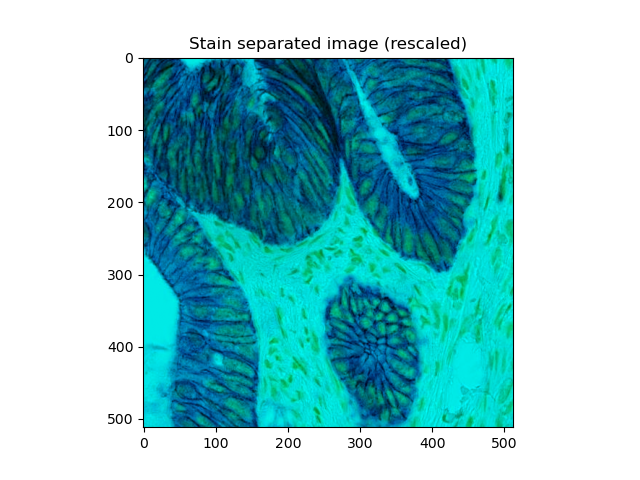

In [68]:
import numpy as np
from skimage.exposure import rescale_intensity

# Rescale hematoxylin and DAB signals and give them a fluorescence look
h = rescale_intensity(ihc_rgb[:, :, 0], out_range=(0, 1))
d = rescale_intensity(ihc_rgb[:, :, 2], out_range=(0, 1))
zdh = np.dstack((np.zeros_like(h), d, h))

fig, ax = plt.subplots()
ax.imshow(zdh)
ax.set_title("Stain separated image (rescaled)")
#ax.axis('off')
plt.show()

# [`NiBabel`](https://nipy.org/nibabel) og [`Nilearn`](https://nilearn.github.io): Neuroimaging in Python

In [69]:
import nibabel as nib
import nilearn

print('nibabel version:', nib.__version__)
print('nilearn version:', nilearn.__version__)

nibabel version: 5.3.2
nilearn version: 0.13.0


In [70]:
img = nib.load('./assets/0.0-test_nifti.nii.gz')

In [71]:
img.shape

(256, 256, 150)

In [72]:
from nibabel.viewers import OrthoSlicer3D

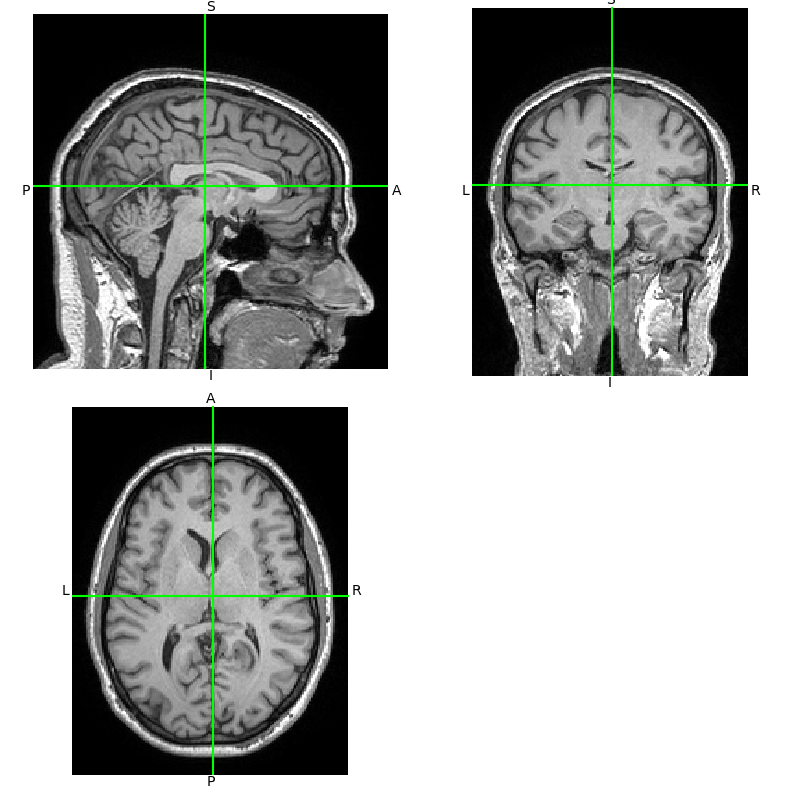

In [73]:
OrthoSlicer3D(img.get_fdata(), affine= img.affine).show()

In [74]:
# To ignore an unimportant warning generated by the below code 
# (remove the filter if you're curious)
import warnings 
warnings.simplefilter('ignore')

In [75]:
from nilearn import datasets, plotting
img = datasets.fetch_localizer_button_task()['tmap']
plotting.view_img_on_surf(img, threshold='90%', surf_mesh='fsaverage')

[fetch_localizer_button_task] Dataset found in /Users/arvid/nilearn_data/brainomics_localizer

[view_img_on_surf] Dataset found in /Users/arvid/nilearn_data/fsaverage

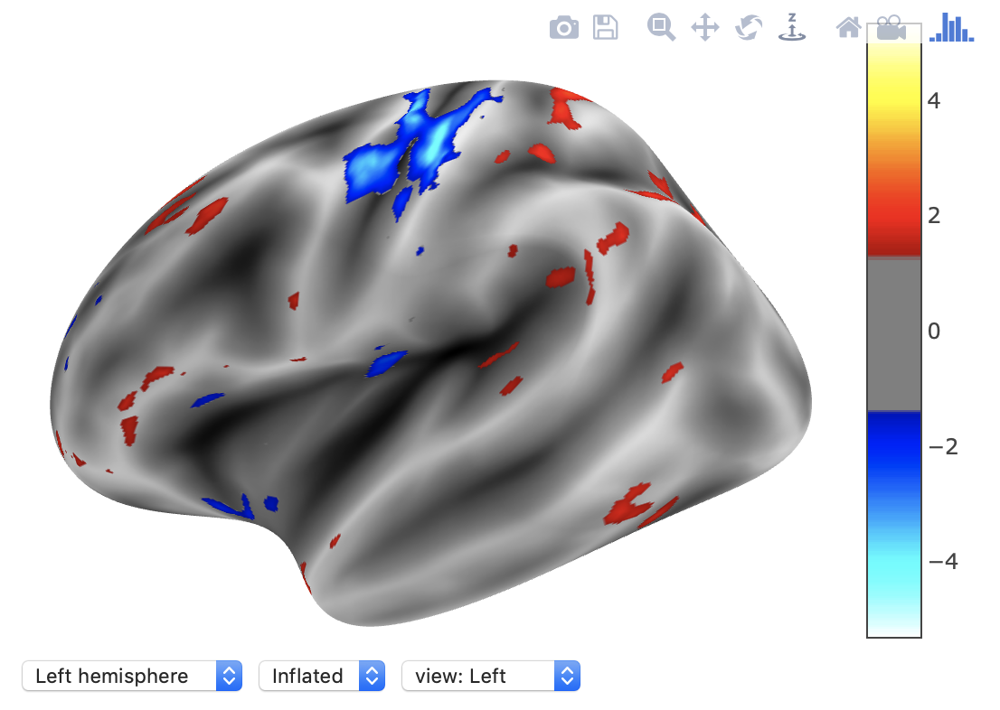

In [76]:
from IPython.display import Image
Image(filename='assets/test_view_img_on_surf.png', width=600)

## $\rightarrow$ Side step:

### Read and display images ["scraped from web"](https://www.google.com/search?sxsrf=ALeKk01eeMXnBMpzAxmG8Hx3KzYXQquTvQ:1585050816400&q=%22images+scraped+from+web%22&tbm=isch&source=univ&sa=X&ved=2ahUKEwiY4fK2hrPoAhUk06YKHdZwDA0QsAR6BAgJEAE&biw=2167&bih=1555), here Wikipedia
e.g. https://en.wikipedia.org/wiki/Magnetic_resonance_imaging

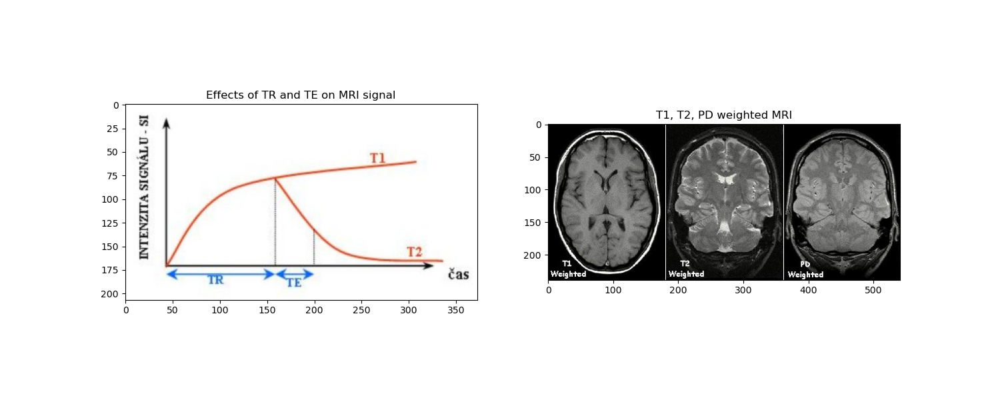

In [77]:
import urllib.request
import io
import time

# Download images with proper User-Agent header to avoid 403 Forbidden error
def download_image(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'})
    with urllib.request.urlopen(req) as response:
        img_data = response.read()
    return imageio.imread(io.BytesIO(img_data))

# Use full resolution URLs instead of thumbnails to avoid rate limiting
im1 = download_image('https://upload.wikimedia.org/wikipedia/commons/4/4d/TR_TE.jpg')
time.sleep(1)  # Small delay to avoid rate limiting
im2 = download_image('https://upload.wikimedia.org/wikipedia/commons/0/03/T1t2PD.jpg')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes.ravel()
ax[0].imshow(im1)
ax[0].set_title("Effects of TR and TE on MRI signal")
ax[1].imshow(im2)
ax[1].set_title("T1, T2, PD weighted MRI")
plt.show()

#### The following three examples extend the learning experience by:

1. **Connecting to Neuroscience**: The receptive field simulation shows how digital image processing relates to biological vision.

2. **Medical Image Handling**: The format converter demonstrates practical aspects of working with medical image formats and their metadata.

3. **Complete Pipeline**: The advanced processing pipeline shows how different image processing concepts work together in a real application.


### Receptive Field Simulation
This example demonstrates how visual neurons process information, connecting biological vision to digital image processing:

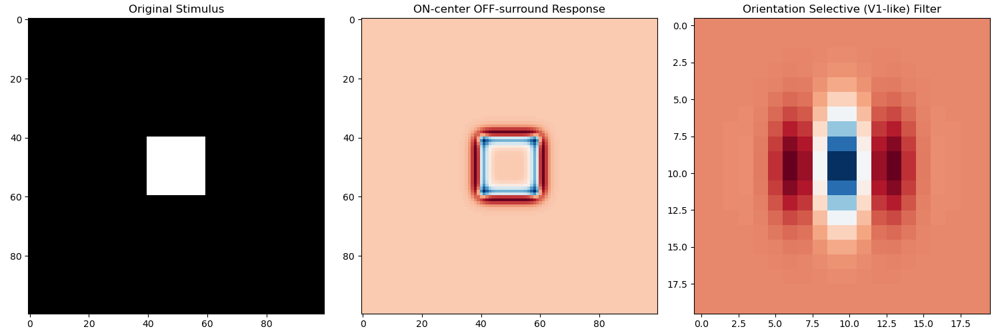

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def create_receptive_field_simulation():
    """Simulate different types of receptive fields found in the visual cortex"""
    
    # Create a simple image
    size = 100
    image = np.zeros((size, size))
    image[40:60, 40:60] = 1  # Create a square stimulus
    
    # Create different types of receptive fields
    x, y = np.meshgrid(np.linspace(-4, 4, 20), np.linspace(-4, 4, 20))
    
    # ON-center OFF-surround
    on_center = gaussian_filter(image, sigma=1) - gaussian_filter(image, sigma=2)
    
    # Orientation selective (similar to V1 simple cells)
    gabor = np.exp(-(x**2 + y**2)/2) * np.cos(2*np.pi*0.3*x)
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original Stimulus')
    
    axes[1].imshow(on_center, cmap='RdBu')
    axes[1].set_title('ON-center OFF-surround Response')
    
    axes[2].imshow(gabor, cmap='RdBu')
    axes[2].set_title('Orientation Selective (V1-like) Filter')
    
    plt.tight_layout()
    plt.show()

create_receptive_field_simulation()

This code simulates and visualizes different types of receptive fields found in the visual cortex of the brain. Let me break it down:

1. **Original Stimulus Creation**:
```python
size = 100
image = np.zeros((size, size))  # Create a 100x100 black image
image[40:60, 40:60] = 1        # Create a white square in the middle
```
This creates a simple black image with a white square in the center, which serves as the visual stimulus.

2. **Receptive Field Types**:

a) **ON-center OFF-surround**:
```python
on_center = gaussian_filter(image, sigma=1) - gaussian_filter(image, sigma=2)
```
- This creates a receptive field that responds strongly to light in the center and is inhibited by light in the surrounding area
- It's created by subtracting two Gaussian filters of different sizes
- This type of receptive field is common in early visual processing (retina and LGN)

b) **Orientation Selective (V1-like)**:
```python
gabor = np.exp(-(x**2 + y**2)/2) * np.cos(2*np.pi*0.3*x)
```
- Creates a Gabor filter that simulates V1 simple cells
- These cells respond best to edges or bars of specific orientations
- Combines a Gaussian envelope with a cosine wave
- Common in primary visual cortex (V1)

3. **Visualization**:
```python
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
```
Creates a figure with three subplots showing:
- Left: Original stimulus (white square)
- Middle: ON-center OFF-surround response (shows edge enhancement)
- Right: Orientation selective filter (shows vertical stripe pattern)

The results show:
1. The original black and white square stimulus
2. The ON-center OFF-surround response showing enhanced edges of the square (red/blue indicates excitation/inhibition)
3. The orientation-selective (Gabor) filter shows:
    - A central vertical band (blue/white)
    - Flanking regions on either side (red)
    - The pattern gradually fades out (becomes more pink/neutral) as you move away from the center
    - This Gabor filter would respond most strongly to vertical edges or bars in an image, not diagonal ones as I incorrectly stated. The orientation selectivity is clearly vertical (0 or 180 degrees), and this type of filter would be most responsive to vertical lines or edges in the visual input.
    - This is similar to how certain V1 simple cells in the visual cortex are specifically tuned to detect vertical orientations in the visual field. 
    - Different V1 neurons would have Gabor-like receptive fields oriented at different angles (horizontal, diagonal, etc.), but this particular example shows a vertically-oriented one.

This simulation demonstrates how different types of neurons in the visual system process and extract different features from visual input, which is fundamental to how our brain processes visual information.


### Medical Image Format Converter
This example shows how to work with different medical image formats:

In [79]:
import nibabel as nib
import pydicom
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def medical_image_converter(input_path, output_path, input_format='dicom', output_format='nifti'):
    """
    Convert between medical image formats and visualize metadata
    """
    # Load image based on input format
    if input_format.lower() == 'dicom':
        # Load DICOM
        dcm = pydicom.dcmread(input_path)
        image_data = dcm.pixel_array
        
        # Display DICOM metadata
        print("DICOM Metadata:")
        print(f"Patient ID: {dcm.PatientID}")
        print(f"Modality: {dcm.Modality}")
        print(f"Image Size: {dcm.Rows}x{dcm.Columns}")
        
    elif input_format.lower() == 'nifti':
        # Load NIfTI
        nii = nib.load(input_path)
        image_data = nii.get_fdata()
        
        # Display NIfTI metadata
        print("NIfTI Metadata:")
        print(f"Affine Matrix:\n{nii.affine}")
        print(f"Image Shape: {nii.shape}")
    
    # Save in output format
    if output_format.lower() == 'nifti':
        # Convert to NIfTI
        new_img = nib.Nifti1Image(image_data, np.eye(4))
        nib.save(new_img, output_path)
    
    # Visualize
    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    plt.imshow(image_data, cmap='gray')
    plt.title('Image Data')
    
    plt.subplot(122)
    plt.hist(image_data.ravel(), bins=50)
    plt.title('Intensity Histogram')
    plt.show()

# Example usage:
# medical_image_converter('input.dcm', 'output.nii.gz')

DICOM Metadata:
Patient ID: Unknown
Modality: NM
Image Size: 256x256


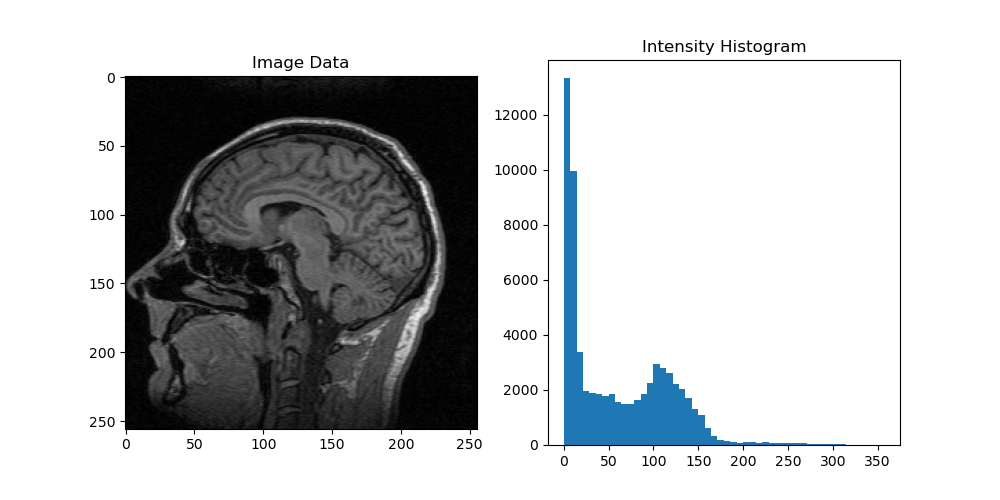

In [80]:
medical_image_converter('./data/mri/flash_060.dcm', './data/flash_060.nii.gz')

file_path = './data/flash_060.nii.gz'

### Advanced Image Processing Pipeline
This example demonstrates a complete image processing pipeline combining multiple concepts:

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import filters, feature, morphology, color, draw  # Added draw import

def advanced_image_processing_pipeline(image):
    """
    Demonstrate a complete image processing pipeline for both RGB and grayscale images
    """
    # Convert RGB to grayscale if needed
    if len(image.shape) == 3:
        gray_image = color.rgb2gray(image)
    else:
        gray_image = image
        
    # Create figure for visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.ravel()
    
    # Show original image
    axes[0].imshow(image)
    axes[0].set_title('Original Image')
    
    # 1. Preprocessing - Gaussian smoothing
    smoothed = ndimage.gaussian_filter(gray_image, sigma=2)
    axes[1].imshow(smoothed, cmap='gray')
    axes[1].set_title('Smoothed Grayscale')
    
    # 2. Edge Detection
    edges = feature.canny(smoothed)
    axes[2].imshow(edges, cmap='gray')
    axes[2].set_title('Edge Detection')
    
    # 3. Thresholding
    thresh = filters.threshold_otsu(smoothed)
    binary = smoothed > thresh
    axes[3].imshow(binary, cmap='gray')
    axes[3].set_title('Thresholded Image')
    
    # 4. Morphological Operations
    opened = morphology.opening(binary)
    axes[4].imshow(opened, cmap='gray')
    axes[4].set_title('Morphological Opening')
    
    # 5. Feature Detection and Visualization
    blobs = feature.blob_dog(smoothed, max_sigma=30, threshold=.1)
    
    # Create a copy of the original image for blob visualization
    blob_img = image.copy() if len(image.shape) == 3 else np.stack([image]*3, axis=-1)
    
    # Draw blobs
    for blob in blobs:
        y, x, r = blob
        y, x = int(y), int(x)
        r = int(r)
        # Draw circle on the image
        rr, cc = draw.circle_perimeter(y, x, r)
        # Make sure indices are within image bounds
        mask = (rr >= 0) & (rr < blob_img.shape[0]) & (cc >= 0) & (cc < blob_img.shape[1])
        rr, cc = rr[mask], cc[mask]
        if len(image.shape) == 3:
            blob_img[rr, cc] = [255, 0, 0]  # Red color for RGB
        else:
            blob_img[rr, cc] = 1  # White for grayscale
            
    axes[5].imshow(blob_img)
    axes[5].set_title('Blob Detection')
    
    # Turn off axes and adjust layout
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    return {
        'grayscale': gray_image,
        'edges': edges,
        'binary': binary,
        'opened': opened,
        'blobs': blobs
    }


In [82]:
# Example usage
def process_image_example(file_path):
    """
    Example of using the pipeline with proper error handling
    """
    try:
        # Load image
        image = plt.imread(file_path)
        print(f"Image shape: {image.shape}")
        print(f"Image dtype: {image.dtype}")
        
        # Process image
        results = advanced_image_processing_pipeline(image)
        
        # Print some statistics
        print("\nProcessing Results:")
        print(f"Number of detected blobs: {len(results['blobs'])}")
        print(f"Edge density: {np.mean(results['edges']):.3f}")
        
        return results
        
    except Exception as e:
        print(f"Error processing image: {e}")
        return None

Image shape: (533, 800, 3)
Image dtype: uint8


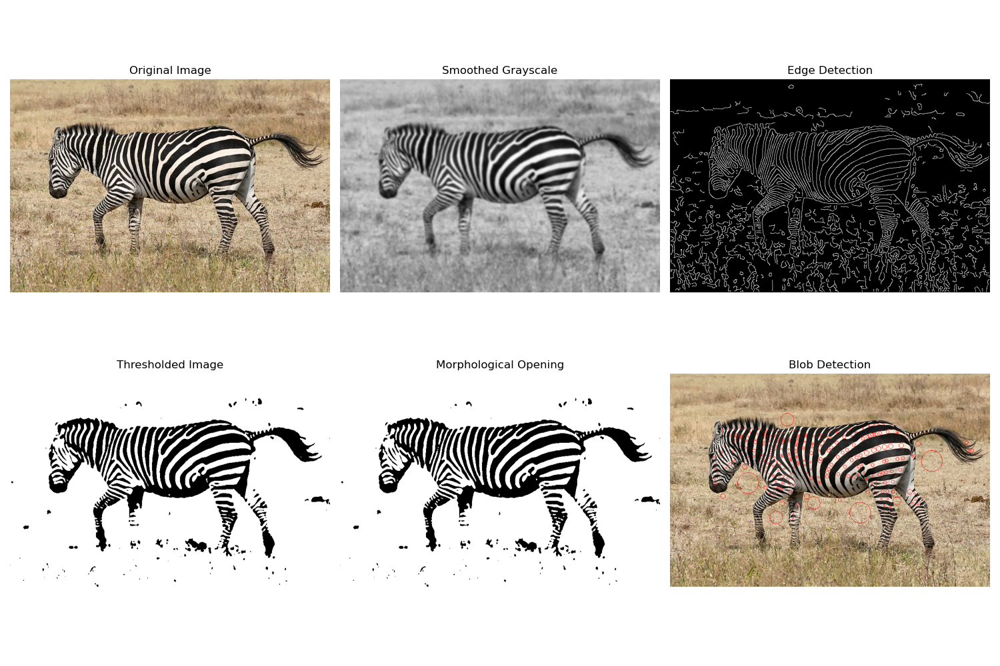


Processing Results:
Number of detected blobs: 321
Edge density: 0.083


In [83]:
# Use the pipeline
file_path = './assets/Zebra_running_Ngorongoro.jpg'
results = process_image_example(file_path)

### A pipline for cell segmentation using open datasets  

Creating synthetic cell image...


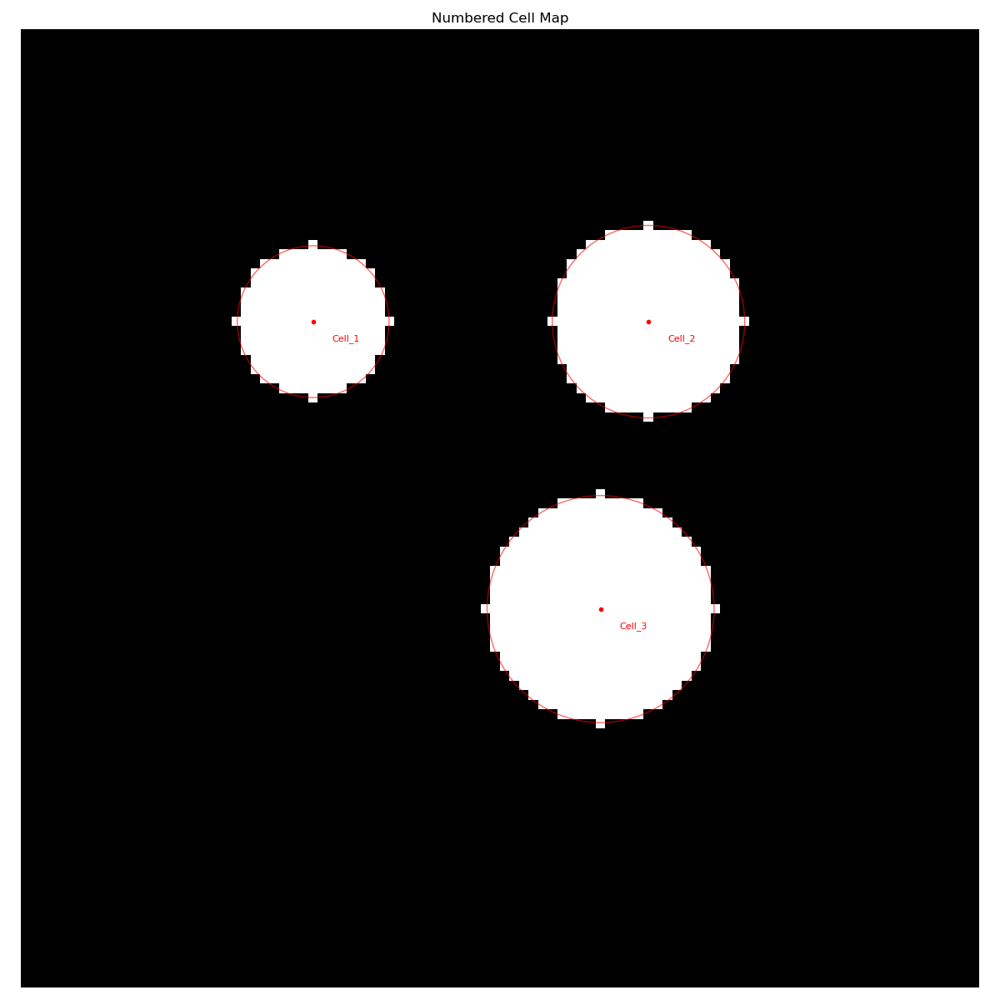


Cell Measurements:
         Area  Perimeter  Eccentricity  Centroid_Y  Centroid_X  \
Cell_1  197.0  52.284271           0.0        30.0        30.0   
Cell_2  317.0  65.941125           0.0        30.0        65.0   
Cell_3  441.0  77.254834           0.0        60.0        60.0   

        Major_Axis_Length  Minor_Axis_Length  Orientation  
Cell_1          15.846984          15.846984    -0.785398  
Cell_2          20.101948          20.101948    -0.785398  
Cell_3          23.695728          23.695728    -0.785398  


In [84]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, morphology, measure, segmentation, color, data
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.util import img_as_float
import pandas as pd

def create_synthetic_cell_image():
    """Create a synthetic test image with cell-like structures of varying sizes"""
    # Create empty image
    image = np.zeros((100, 100))
    
    # Define centers and radii for three cells (different sizes)
    cells = [
        (30, 30, 8),   # small cell
        (60, 60, 12),  # large cell
        (30, 65, 10),  # medium cell
    ]
    
    # Create circular cells with different radii
    for center_y, center_x, radius in cells:
        y, x = np.ogrid[-center_y:100-center_y, -center_x:100-center_x]
        mask = x*x + y*y <= radius*radius
        image[mask] = 1
        
    return image

def segment_cells(image):
    """Segment cells and return labels and properties"""
    image = img_as_float(image)
    smooth = filters.gaussian(image, sigma=1)
    thresh = filters.threshold_otsu(smooth)
    binary = smooth > thresh
    distance = ndimage.distance_transform_edt(binary)
    coordinates = peak_local_max(distance, min_distance=20, labels=binary)
    local_max = np.zeros_like(distance, dtype=bool)
    local_max[tuple(coordinates.T)] = True
    markers = measure.label(local_max)
    labels = watershed(-distance, markers, mask=binary)
    props = measure.regionprops(labels, image)
    return labels, props

def visualize_numbered_cells(image, props):
    """Create a single figure with numbered cells"""
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.imshow(image, cmap='gray')
    
    for i, prop in enumerate(props, 1):
        y, x = prop.centroid
        ax.plot(x, y, 'r.')
        ax.add_patch(plt.Circle((x, y), prop.equivalent_diameter/2, 
                              color='r', fill=False, alpha=0.6))
        ax.text(x + 2, y + 2, f'Cell_{i}', color='red', fontsize=8,
               bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    
    ax.set_title('Numbered Cell Map')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Main execution
try:
    # Create and segment synthetic image
    print("Creating synthetic cell image...")
    cell_image = create_synthetic_cell_image()
    labels, props = segment_cells(cell_image)
    
    # Create DataFrame with measurements
    cell_data = {
        'Area': [prop.area for prop in props],
        'Perimeter': [prop.perimeter for prop in props],
        'Eccentricity': [prop.eccentricity for prop in props],
        'Centroid_Y': [prop.centroid[0] for prop in props],
        'Centroid_X': [prop.centroid[1] for prop in props],
        'Major_Axis_Length': [prop.major_axis_length for prop in props],
        'Minor_Axis_Length': [prop.minor_axis_length for prop in props],
        'Orientation': [prop.orientation for prop in props]
    }
    
    # Create DataFrame with proper indexing
    df = pd.DataFrame(cell_data)
    df.index = [f'Cell_{i+1}' for i in range(len(props))]
    
    # Display numbered cells and measurements
    visualize_numbered_cells(cell_image, props)
    print("\nCell Measurements:")
    print(df)

except Exception as e:
    print(f"Error: {str(e)}")

Creating synthetic cell image...


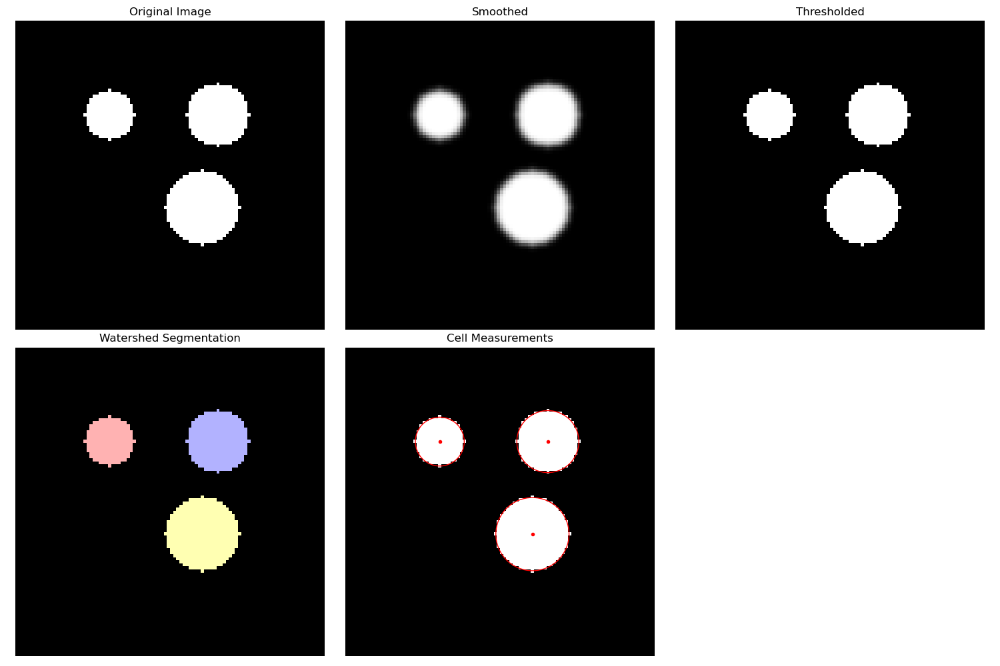


Cell Measurements:
         Area  Perimeter  Eccentricity  Centroid_Y  Centroid_X  \
Cell_1  197.0  52.284271           0.0        30.0        30.0   
Cell_2  317.0  65.941125           0.0        30.0        65.0   
Cell_3  441.0  77.254834           0.0        60.0        60.0   

        Major_Axis_Length  Minor_Axis_Length  Orientation  
Cell_1          15.846984          15.846984    -0.785398  
Cell_2          20.101948          20.101948    -0.785398  
Cell_3          23.695728          23.695728    -0.785398  


In [85]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, morphology, measure, segmentation, color, data
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.util import img_as_float
import pandas as pd

def create_synthetic_cell_image():
    """Create a synthetic test image with cell-like structures of varying sizes"""
    image = np.zeros((100, 100))
    # Define centers and radii for three cells (different sizes)
    cells = [
        (30, 30, 8),   # small cell
        (60, 60, 12),  # large cell
        (30, 65, 10),  # medium cell
    ]
    for center_y, center_x, radius in cells:
        selem = morphology.disk(radius)
        rr, cc = np.where(selem > 0)
        rr = rr + center_y - radius
        cc = cc + center_x - radius
        mask = (rr >= 0) & (rr < image.shape[0]) & (cc >= 0) & (cc < image.shape[1])
        rr, cc = rr[mask], cc[mask]
        image[rr, cc] = 1
    return image

def cell_segmentation_demo(image):
    """Demonstrate cell segmentation with detailed steps"""
    # Convert to float
    image = img_as_float(image)
    
    # Create figure for visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    ax = axes.ravel()
    
    # 1. Original image
    ax[0].imshow(image, cmap='gray')
    ax[0].set_title('Original Image')
    
    # 2. Gaussian smoothing
    smooth = filters.gaussian(image, sigma=1)
    ax[1].imshow(smooth, cmap='gray')
    ax[1].set_title('Smoothed')
    
    # 3. Threshold
    thresh = filters.threshold_otsu(smooth)
    binary = smooth > thresh
    ax[2].imshow(binary, cmap='gray')
    ax[2].set_title('Thresholded')
    
    # 4. Distance transform
    distance = ndimage.distance_transform_edt(binary)
    
    # 5. Find local maxima
    coordinates = peak_local_max(distance, min_distance=20, labels=binary)
    local_max = np.zeros_like(distance, dtype=bool)
    local_max[tuple(coordinates.T)] = True
    markers = measure.label(local_max)
    
    # 6. Watershed segmentation
    labels = watershed(-distance, markers, mask=binary)
    ax[3].imshow(color.label2rgb(labels, image=image, alpha=0.3))
    ax[3].set_title('Watershed Segmentation')
    
    # Get region properties
    props = measure.regionprops(labels, image)
    
    # Show measurements
    ax[4].imshow(image, cmap='gray')
    for prop in props:
        y, x = prop.centroid
        ax[4].plot(x, y, 'r.')
        ax[4].add_patch(plt.Circle((x, y), prop.equivalent_diameter/2, 
                                 color='r', fill=False))
    ax[4].set_title('Cell Measurements')
    
    # Turn off axes
    for a in ax:
        a.axis('off')
    ax[5].axis('off')  # For the unused subplot
    
    plt.tight_layout()
    plt.show()
    
    return labels, props

# Create and process synthetic image
try:
    print("Creating synthetic cell image...")
    cell_image = create_synthetic_cell_image()
    labels, props = cell_segmentation_demo(cell_image)
    
    # Create DataFrame with measurements
    cell_data = {
        'Area': [prop.area for prop in props],
        'Perimeter': [prop.perimeter for prop in props],
        'Eccentricity': [prop.eccentricity for prop in props],
        'Centroid_Y': [prop.centroid[0] for prop in props],
        'Centroid_X': [prop.centroid[1] for prop in props],
        'Major_Axis_Length': [prop.major_axis_length for prop in props],
        'Minor_Axis_Length': [prop.minor_axis_length for prop in props],
        'Orientation': [prop.orientation for prop in props]
    }
    
    # Create DataFrame with proper indexing
    df = pd.DataFrame(cell_data)
    df.index = [f'Cell_{i+1}' for i in range(len(props))]
    
    print("\nCell Measurements:")
    print(df)
    
except Exception as e:
    print(f"Error: {str(e)}")

### Interactive cell inspection (widget) - WIP

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, morphology, measure, segmentation, color, data, exposure
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.util import img_as_float
import ipywidgets as widgets
from IPython.display import display

def cell_segmentation_demo(image):
    """Your existing cell_segmentation_demo function remains unchanged"""
    # ... (keep all the existing code)
    return labels, props

def interactive_cell_inspection(image, labels, props):
    """
    Interactive cell visualization.
    Click on a cell label in the plot to see its measurements
    in the info panel below the figure.
    """
    # Wrap everything in an Output widget so we can fully clear it on close
    fig_output = widgets.Output()
    info_html = widgets.HTML(value='<i>Click a cell label above to see its measurements.</i>')
    btn_clear = widgets.Button(description='Clear info', button_style='warning', icon='eraser')
    btn_close = widgets.Button(description='Close figure', button_style='danger', icon='times')
    button_bar = widgets.HBox([btn_clear, btn_close])
    container = widgets.VBox([fig_output, button_bar, info_html])

    cell_data = {}  # map label artist -> info string

    with fig_output:
        fig, ax = plt.subplots(figsize=(8, 7))
        ax.imshow(image, cmap='gray')

        for i, prop in enumerate(props, 1):
            y, x = prop.centroid
            ax.plot(x, y, 'r.', markersize=5)
            ax.add_patch(plt.Circle((x, y), prop.equivalent_diameter / 2,
                                    color='r', fill=False, linewidth=1.5, linestyle='--'))
            lbl = ax.text(x + 3, y + 3, f'Cell_{i}',
                          color='white', fontsize=10, fontweight='bold',
                          bbox=dict(facecolor='black', alpha=0.5, pad=2, edgecolor='none'),
                          picker=True)

            cell_data[lbl] = (
                f'<b>Cell_{i}</b><br>'
                f'&nbsp;&nbsp;Area: {prop.area:.1f}<br>'
                f'&nbsp;&nbsp;Perimeter: {prop.perimeter:.1f}<br>'
                f'&nbsp;&nbsp;Eccentricity: {prop.eccentricity:.3f}<br>'
                f'&nbsp;&nbsp;Major Axis: {prop.major_axis_length:.1f}<br>'
                f'&nbsp;&nbsp;Minor Axis: {prop.minor_axis_length:.1f}<br>'
                f'&nbsp;&nbsp;Orientation: {prop.orientation:.3f}<br>'
                f'&nbsp;&nbsp;Solidity: {prop.solidity:.3f}<br>'
                f'&nbsp;&nbsp;Extent: {prop.extent:.3f}'
            )

        def on_pick(event):
            if event.artist in cell_data:
                info_html.value = cell_data[event.artist]

        fig.canvas.mpl_connect('pick_event', on_pick)

        ax.set_title(
            f'Cell Map  \u2014  click any Cell_X label  |  Total cells: {len(props)}',
            fontsize=13, loc='left')
        ax.axis('off')
        fig.tight_layout()
        plt.show()

    def on_clear(_):
        info_html.value = '<i>Cleared.</i>'

    def on_close(_):
        plt.close(fig)
        container.close()

    btn_clear.on_click(on_clear)
    btn_close.on_click(on_close)

    display(container)

# Run
try:
    interactive_cell_inspection(cell_image, labels, props)
except Exception as e:
    print(f"Error: {e}")
